In [ ]:
#imports block
import math
import heapq
import pandas as pd
import numpy as np
import random
from sympy import symbols, Eq, solve
from scipy.optimize import root_scalar
from IPython.display import display, HTML
from scipy.stats import probplot
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import truncnorm
from datetime import timedelta, datetime, time
from contextlib import closing
import heapq
from enum import Enum
from datetime import timedelta


# **התאמת התפלגות**

FriendsGroup data:
    minutes  Unnamed: 1
0  1.788132    0.729271
1  2.961514         NaN
2  1.124513         NaN
3  0.298724         NaN
4  2.313455         NaN
Index(['minutes', 'Unnamed: 1'], dtype='object')

MainStage data:
     minutes  Unnamed: 1
0  27.305066   45.902765
1  54.992807    8.927433
2  43.730419         NaN
3  49.107227         NaN
4  48.366694         NaN
Index(['minutes', 'Unnamed: 1'], dtype='object')


FriendsGroup Arrival Intervals
Lambda MLE: 0.7292706992898642


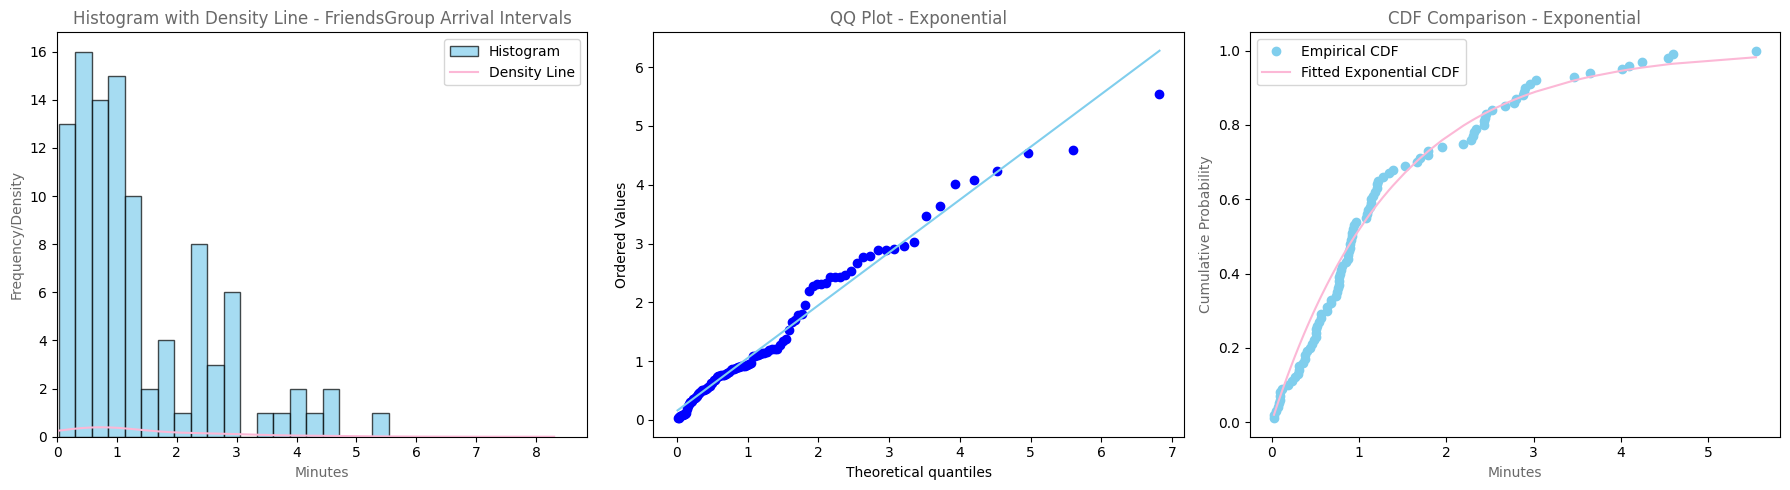

MainStage Concert Duration
Mu MLE: 45.90276537893928
Sigma MLE: 8.927433217558212


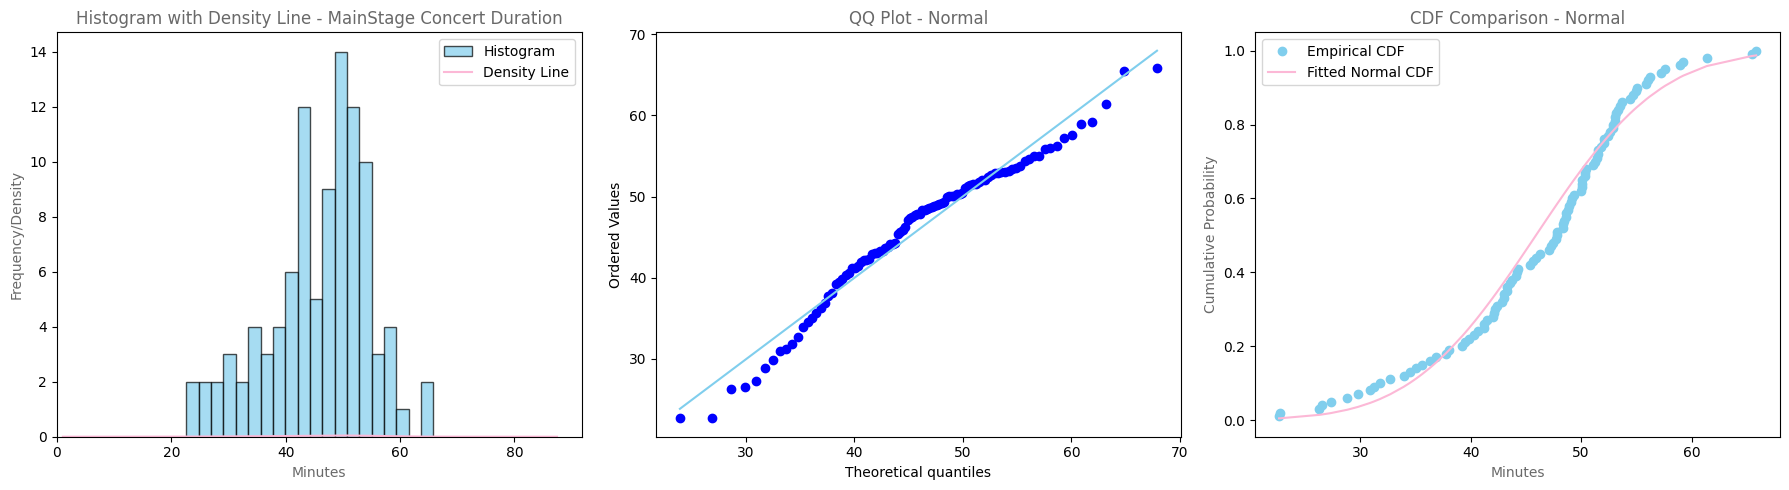

In [ ]:
import os

if os.path.exists("samples_for_simulation.xlsx"):
    # ==============================
    # Imports
    # ==============================
    import pandas as pd
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.stats import probplot, norm
    from IPython.display import display, HTML

    # ==============================
    # Read Excel sheets
    # ==============================
    # Load historical data collected from previous festival years.
    excel_file = "samples_for_simulation.xlsx"

    friends_data = pd.read_excel(excel_file, sheet_name="FriendsGroup_arrival_intervals")
    mainstage_data = pd.read_excel(excel_file, sheet_name="MainStage_concert_duration")

    print("FriendsGroup data:")
    print(friends_data.head())
    print(friends_data.columns)

    print("\nMainStage data:")
    print(mainstage_data.head())
    print(mainstage_data.columns)

    column_name = "minutes"

    # ==============================
    # Colors
    # ==============================
    # Consistent color scheme used across all plots.
    unified_blue = "#80CEED"
    unified_pink = "#FCB8D6"

    # ==============================
    # General histogram
    # ==============================
    def histogram_and_density_line(data, title, ax):
        # Plot histogram with a KDE density line overlay.
        ax.hist(data, bins=20, edgecolor='black', alpha=0.7,
                label='Histogram', color=unified_blue)

        data.plot(kind='kde', color=unified_pink,
                  label='Density Line', bw_method=0.5, ax=ax)

        ax.set_title(title, color='dimgray')
        ax.set_xlabel("Minutes", color='dimgray')
        ax.set_ylabel("Frequency/Density", color='dimgray')
        ax.set_xlim(left=0)
        ax.legend()


    # ==============================
    # Exponential distribution plots
    # For FriendsGroup arrival intervals
    # ==============================
    def MLE_for_lambda(data):
        # MLE estimate for exponential lambda: lambda = 1 / mean.
        return 1 / data.mean()

    def QQ_plot_exponential(data, lambda_mle, ax):
        # QQ plot comparing data against fitted exponential distribution.
        probplot(data, dist="expon", sparams=(0, 1 / lambda_mle), plot=ax)
        ax.get_lines()[1].set_color(unified_blue)
        ax.set_title("QQ Plot - Exponential", color='dimgray')

    def CDF_plot_exponential(data, lambda_mle, ax):
        # Plot empirical CDF vs fitted exponential CDF.
        sorted_data = np.sort(data)
        empirical_cdf = np.arange(1, len(data) + 1) / len(data)
        fitted_cdf = 1 - np.exp(-lambda_mle * sorted_data)

        ax.plot(sorted_data, empirical_cdf, marker='o', linestyle='',
                label='Empirical CDF', color=unified_blue)

        ax.plot(sorted_data, fitted_cdf, linestyle='-',
                label='Fitted Exponential CDF', color=unified_pink)

        ax.set_title("CDF Comparison - Exponential", color='dimgray')
        ax.set_xlabel("Minutes", color='dimgray')
        ax.set_ylabel("Cumulative Probability", color='dimgray')
        ax.legend(loc='upper left')


    # ==============================
    # Normal distribution plots
    # For MainStage concert duration
    # ==============================
    def MLE_for_normal(data):
        # MLE estimates for normal distribution: mu = mean, sigma = std with ddof=0.
        mu = data.mean()
        sigma = data.std(ddof=0)
        return mu, sigma

    def QQ_plot_normal(data, mu, sigma, ax):
        # QQ plot comparing data against fitted normal distribution.
        probplot(data, dist="norm", sparams=(mu, sigma), plot=ax)
        ax.get_lines()[1].set_color(unified_blue)
        ax.set_title("QQ Plot - Normal", color='dimgray')

    def CDF_plot_normal(data, mu, sigma, ax):
        # Plot empirical CDF vs fitted normal CDF.
        sorted_data = np.sort(data)
        empirical_cdf = np.arange(1, len(data) + 1) / len(data)
        fitted_cdf = norm.cdf(sorted_data, loc=mu, scale=sigma)

        ax.plot(sorted_data, empirical_cdf, marker='o', linestyle='',
                label='Empirical CDF', color=unified_blue)

        ax.plot(sorted_data, fitted_cdf, linestyle='-',
                label='Fitted Normal CDF', color=unified_pink)

        ax.set_title("CDF Comparison - Normal", color='dimgray')
        ax.set_xlabel("Minutes", color='dimgray')
        ax.set_ylabel("Cumulative Probability", color='dimgray')
        ax.legend(loc='upper left')


    # ==============================
    # FriendsGroup arrival intervals
    # ==============================
    display(HTML("<h1 style='text-align: center; color: #FCB8D6;'>FriendsGroup Arrival Intervals - Graphical Comparison</h1>"))

    # Clean data and estimate lambda using MLE.
    friends_minutes = pd.to_numeric(friends_data[column_name], errors='coerce').dropna()
    friends_minutes = friends_minutes[friends_minutes >= 0]

    lambda_friends = MLE_for_lambda(friends_minutes)

    print("FriendsGroup Arrival Intervals")
    print("Lambda MLE:", lambda_friends)

    # Plot histogram, QQ plot, and CDF comparison side by side.
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    histogram_and_density_line(
        friends_minutes,
        "Histogram with Density Line - FriendsGroup Arrival Intervals",
        axs[0]
    )

    QQ_plot_exponential(friends_minutes, lambda_friends, axs[1])
    CDF_plot_exponential(friends_minutes, lambda_friends, axs[2])

    plt.tight_layout()
    plt.show()


    # ==============================
    # MainStage concert duration
    # ==============================
    display(HTML("<h1 style='text-align: center; color: #FCB8D6;'>MainStage Concert Duration - Graphical Comparison</h1>"))

    # Clean data and estimate mu and sigma using MLE.
    mainstage_minutes = pd.to_numeric(mainstage_data[column_name], errors='coerce').dropna()
    mainstage_minutes = mainstage_minutes[mainstage_minutes >= 0]

    mu_mainstage, sigma_mainstage = MLE_for_normal(mainstage_minutes)

    print("MainStage Concert Duration")
    print("Mu MLE:", mu_mainstage)
    print("Sigma MLE:", sigma_mainstage)

    # Plot histogram, QQ plot, and CDF comparison side by side.
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))

    histogram_and_density_line(
        mainstage_minutes,
        "Histogram with Density Line - MainStage Concert Duration",
        axs[0]
    )

    QQ_plot_normal(mainstage_minutes, mu_mainstage, sigma_mainstage, axs[1])
    CDF_plot_normal(mainstage_minutes, mu_mainstage, sigma_mainstage, axs[2])

    plt.tight_layout()
    plt.show()
else:
    print("samples_for_simulation.xlsx was not found, so this section is skipped. "
          "It needs the course data file in the same folder. The simulation below does not depend on it "
          "(the fitted parameters are set in the base-case configuration), and this notebook keeps the saved outputs "
          "of the original run.")


<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

## ניתוח התפלגות עבור מרווחי ההגעה של קבוצות חברים ומשך ההופעות בבמה המרכזית

---

### **מרווחי הגעה של קבוצות חברים**

#### **היסטוגרמה:**

בניתוח מרווחי ההגעה של קבוצות החברים, ההיסטוגרמה מציגה דפוס המזכיר התפלגות מעריכית – דבר שמתיישב היטב עם אופי תהליך ההגעה של ישויות למערכת.

ניתן לזהות ריכוז גבוה של תצפיות סביב ערכים נמוכים, כאשר השכיחות פוחתת בהדרגה ככל שמרווח הזמן בין ההגעות גדל. תבנית זו מאפיינת התפלגות אקספוננציאלית, שבה רוב מרווחי ההגעה קצרים יחסית, אך קיימים גם מרווחים ארוכים יותר בתדירות נמוכה.

---

#### **QQ Plot:**

עבור מרווחי ההגעה של קבוצות החברים, ניתן לראות התאמה טובה לערכים הנמוכים והבינוניים של ההתפלגות האקספוננציאלית.

עם זאת, בזנבות – בעיקר עבור הערכים הגבוהים – קיימת סטייה מסוימת מהקו התיאורטי, המעידה על אי התאמה חלקית באזורים אלו.

---

#### **התאמה לפונקציה המצטברת (CDF):**

גם בהשוואה בין ההתפלגות האמפירית לבין הפונקציה המצטברת של ההתפלגות האקספוננציאלית, נצפית התאמה כללית טובה.

עם זאת, קיימים אזורים שבהם ההצטברות של הנתונים בפועל שונה במעט מזו הצפויה לפי המודל התאורטי, אך הפערים אינם משמעותיים.

---

#### **סיכום:**

על סמך ההיסטוגרמה, גרף ה־QQ וגרף ה־CDF, ניתן לומר כי קיימת סבירות גבוהה לכך שמרווחי ההגעה של קבוצות החברים מתפלגים לפי **התפלגות אקספוננציאלית**.

---

### **משך ההופעות בבמה המרכזית**

#### **היסטוגרמה:**

בניתוח משך ההופעות בבמה המרכזית, ההיסטוגרמה מציגה צורה סימטרית יחסית סביב ערך מרכזי, דבר המאפיין התפלגות נורמלית.

רוב משכי ההופעות מרוכזים סביב הערכים האמצעיים, כאשר ככל שמתרחקים מהממוצע השכיחות פוחתת בהדרגה לשני הכיוונים.

---

#### **QQ Plot:**

בגרף ה־QQ ניתן לראות שרוב הנקודות נמצאות בקרבת הקו התיאורטי, דבר המעיד על התאמה טובה להתפלגות נורמלית.

קיימות סטיות מסוימות בקצוות ההתפלגות, בעיקר עבור ההופעות הקצרות והארוכות ביותר, אך הן אינן חריגות באופן משמעותי.

---

#### **התאמה לפונקציה המצטברת (CDF):**

בהשוואה בין ההתפלגות האמפירית לבין הפונקציה המצטברת של ההתפלגות הנורמלית, מתקבלת התאמה טובה לאורך רוב תחום הנתונים.

למרות שקיימים הבדלים קטנים באזורים מסוימים, צורת ההצטברות הכללית דומה לזו של ההתפלגות הנורמלית.

---

#### **סיכום:**

על סמך ההיסטוגרמה, גרף ה־QQ וגרף ה־CDF, ניתן לומר כי קיימת סבירות גבוהה לכך שמשך ההופעות בבמה המרכזית מתפלג לפי **התפלגות נורמלית**.

</div>


<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

## **מציאת פרמטרים לפי MLE**

---


## אומדן סבירות מרבית (MLE) עבור מרווחי ההגעה של קבוצות החברים

מאחר שמרווחי ההגעה נמצאו מתאימים להתפלגות אקספוננציאלית, חושב פרמטר הקצב באמצעות שיטת אומדן הסבירות המרבית (MLE).

### **פונקציית צפיפות ההסתברות (PDF):**

$$
f(x;\lambda)=
\begin{cases}
\lambda e^{-\lambda x}, & x\ge0 \\
0, & x<0
\end{cases}
$$

כאשר:

$$
\lambda > 0
$$

הוא פרמטר הקצב של ההתפלגות.

---

### **פונקציית הסבירות (Likelihood):**

בהינתן מדגם:

$$
x_1,x_2,\ldots,x_n
$$

פונקציית הסבירות היא:

$$
L(\lambda)=\prod_{i=1}^{n}\lambda e^{-\lambda x_i}
=\lambda^n e^{-\lambda\sum_{i=1}^{n}x_i}
$$

---

### **פונקציית הלוג-סבירות (Log-Likelihood):**

$$
\ell(\lambda)
=
n\ln(\lambda)
-
\lambda\sum_{i=1}^{n}x_i
$$

---

### **מציאת אומדן λ:**

נגזור לפי $\lambda$ ונשווה לאפס:

$$
\frac{d\ell(\lambda)}{d\lambda}
=
\frac{n}{\lambda}
-
\sum_{i=1}^{n}x_i
=
0
$$

ולכן:

$$
\lambda
=
\frac{n}{\sum_{i=1}^{n}x_i}
=
\frac{1}{\bar{x}}
$$

---

### **תוצאה:**

עבור נתוני מרווחי ההגעה התקבל:

$$
\lambda_{MLE}=0.72927
$$

---

## אומדן סבירות מרבית (MLE) עבור משך ההופעות בבמה המרכזית

מאחר שמשך ההופעות נמצא מתאים להתפלגות נורמלית, חושבו פרמטרי ההתפלגות באמצעות שיטת MLE.

### **פונקציית צפיפות ההסתברות (PDF):**

$$
f(x;\mu,\sigma)=
\frac{1}{\sigma\sqrt{2\pi}}
e^{-\frac{(x-\mu)^2}{2\sigma^2}}
$$

כאשר:

$$
\mu
$$

הוא ממוצע ההתפלגות, ו-

$$
\sigma
$$

הוא סטיית התקן.

---

### **אומדני MLE:**

עבור ההתפלגות הנורמלית מתקבלים האומדנים:

$$
\hat{\mu}
=
\frac{1}{n}
\sum_{i=1}^{n}x_i
$$

$$
\hat{\sigma}
=
\sqrt{
\frac{1}{n}
\sum_{i=1}^{n}
(x_i-\hat{\mu})^2
}
$$

---

### **תוצאות:**

עבור נתוני משך ההופעות התקבלו:

$$
\mu_{MLE}=45.9028
$$

$$
\sigma_{MLE}=8.9274
$$

---

### **מסקנה:**

הפרמטרים שהתקבלו בשיטת MLE הם:

עבור מרווחי ההגעה של קבוצות החברים:

$$
\lambda = 0.72927
$$

ועבור משך ההופעות בבמה המרכזית:

$$
\mu = 45.9028
$$

$$
\sigma = 8.9274
$$

פרמטרים אלו ישמשו בהמשך לצורך יצירת דגימות אקראיות במסגרת הסימולציה.

</div>

In [ ]:
import os

if os.path.exists("samples_for_simulation.xlsx"):
    # ==============================
    # Goodness-of-Fit Tests
    # FriendsGroup: Exponential KS Test
    # MainStage: Normal KS Test
    # ==============================

    import pandas as pd
    import numpy as np
    from scipy.stats import norm
    from IPython.display import display, HTML

    # Load historical data from the simulation samples file.
    excel_file = "samples_for_simulation.xlsx"

    friends_data = pd.read_excel(excel_file, sheet_name="FriendsGroup_arrival_intervals")
    mainstage_data = pd.read_excel(excel_file, sheet_name="MainStage_concert_duration")

    column_name = "minutes"

    # Clean the data — drop missing values and negative entries.
    friends_minutes = pd.to_numeric(friends_data[column_name], errors="coerce").dropna()
    friends_minutes = friends_minutes[friends_minutes >= 0]

    mainstage_minutes = pd.to_numeric(mainstage_data[column_name], errors="coerce").dropna()
    mainstage_minutes = mainstage_minutes[mainstage_minutes >= 0]


    # ==============================
    # Empirical CDF
    # ==============================
    def empirical_cdf(data):
        # Return sorted data and the corresponding empirical CDF values.
        data_sorted = np.sort(data)
        n = len(data)
        return data_sorted, np.arange(1, n + 1) / n


    # ==============================
    # Theoretical CDFs
    # ==============================
    def exp_cdf(x, lambda_):
        # CDF of Exponential distribution with given lambda.
        return 1 - np.exp(-lambda_ * x)

    def normal_cdf(x, mu, sigma):
        # CDF of Normal distribution with given mean and standard deviation.
        return norm.cdf(x, loc=mu, scale=sigma)


    # ==============================
    # KS Test — Exponential
    # ==============================
    def ks_test_expo(data, cdf, *params):
        # KS test for exponential distribution with estimated parameter.
        # Adjusted statistic from KS table: Expo(X̄(n)).
        n = len(data)
        data_sorted, empirical_cdf_values = empirical_cdf(data)
        theoretical_cdf_values = cdf(data_sorted, *params)
        d_statistic = np.max(np.abs(empirical_cdf_values - theoretical_cdf_values))
        return (np.sqrt(n) + 0.26 + (0.5 / np.sqrt(n))) * (d_statistic - 0.2 / n)


    # ==============================
    # KS Test — Normal
    # ==============================
    def ks_test_normal(data, cdf, *params):
        # KS test for normal distribution with estimated parameters.
        # Adjusted statistic from KS table: N(X̄(n), S²(n)).
        n = len(data)
        data_sorted, empirical_cdf_values = empirical_cdf(data)
        theoretical_cdf_values = cdf(data_sorted, *params)
        d_statistic = np.max(np.abs(empirical_cdf_values - theoretical_cdf_values))
        return (np.sqrt(n) - 0.01 + (0.85 / np.sqrt(n))) * d_statistic


    # ==============================
    # Critical Value
    # ==============================
    def d_critical(alpha, dist_type="expo"):
        # Critical values from KS table.
        # dist_type: "expo" for Expo(X̄(n)), "normal" for N(X̄(n), S²(n)).
        if dist_type == "expo":
            table = {0.15: 0.926, 0.10: 0.990, 0.05: 1.094, 0.025: 1.190, 0.01: 1.308}
        else:
            table = {0.15: 0.775, 0.10: 0.819, 0.05: 0.895, 0.025: 0.955, 0.01: 1.035}
        return table.get(alpha)


    # ==============================
    # Hypothesis Test
    # ==============================
    def hypothesis_test(critical_value, d_statistic):
        # Compare the test statistic to the critical value and print the conclusion.
        if d_statistic > critical_value:
            print(f"{d_statistic:.4f} > {critical_value}")
            print("Therefore, Reject the null hypothesis")
        else:
            print(f"{d_statistic:.4f} < {critical_value}")
            print("Therefore, Fail to reject the null hypothesis")


    # ==============================
    # FriendsGroup Arrival Intervals
    # Exponential KS Test — Alpha = 5%
    # ==============================
    display(HTML("<h2 style='text-align:left; color:orange;'>FriendsGroup Arrival Intervals KS Test</h2>"))

    # Estimate lambda using MLE: lambda = 1 / mean.
    lambda_friends = 1 / friends_minutes.mean()
    d_statistic_friends = ks_test_expo(friends_minutes, exp_cdf, lambda_friends)
    critical_value_friends = d_critical(0.05, dist_type="expo")

    print("Distribution: Exponential")
    print(f"Lambda MLE: {lambda_friends:.5f}")
    print(f"D Statistic: {round(d_statistic_friends, 4)}")
    print(f"Critical Value (Alpha=5%): {critical_value_friends}")
    hypothesis_test(critical_value_friends, d_statistic_friends)


    # ==============================
    # MainStage Concert Duration
    # Normal KS Test — Alpha = 5% and Alpha = 1%
    # ==============================
    display(HTML("<h2 style='text-align:left; color:orange;'>MainStage Concert Duration KS Test</h2>"))

    # Estimate mu and sigma using MLE.
    mu_mainstage = mainstage_minutes.mean()
    sigma_mainstage = mainstage_minutes.std(ddof=0)
    d_statistic_mainstage = ks_test_normal(mainstage_minutes, normal_cdf, mu_mainstage, sigma_mainstage)

    print("Distribution: Normal")
    print(f"Mu MLE:    {mu_mainstage:.4f}")
    print(f"Sigma MLE: {sigma_mainstage:.4f}")
    print(f"D Statistic: {round(d_statistic_mainstage, 4)}")

    # Alpha = 5% — shown to demonstrate rejection at this level.
    critical_value_main_05 = d_critical(0.05, dist_type="normal")
    print(f"\n--- Alpha = 5% ---")
    print(f"Critical Value: {critical_value_main_05}")
    hypothesis_test(critical_value_main_05, d_statistic_mainstage)

    # Alpha = 1% — final decision based on course guidelines.
    critical_value_main_01 = d_critical(0.01, dist_type="normal")
    print(f"\n--- Alpha = 1% ---")
    print(f"Critical Value: {critical_value_main_01}")
    hypothesis_test(critical_value_main_01, d_statistic_mainstage)
else:
    print("samples_for_simulation.xlsx was not found, so this section is skipped. "
          "It needs the course data file in the same folder. The simulation below does not depend on it "
          "(the fitted parameters are set in the base-case configuration), and this notebook keeps the saved outputs "
          "of the original run.")


Distribution: Exponential
Lambda MLE: 0.72927
D Statistic: 0.7884
Critical Value (Alpha=5%): 1.094
0.7884 < 1.094
Therefore, Fail to reject the null hypothesis


Distribution: Normal
Mu MLE:    45.9028
Sigma MLE: 8.9274
D Statistic: 0.9309

--- Alpha = 5% ---
Critical Value: 0.895
0.9309 > 0.895
Therefore, Reject the null hypothesis

--- Alpha = 1% ---
Critical Value: 1.035
0.9309 < 1.035
Therefore, Fail to reject the null hypothesis


<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

### אישוש התפלגות באמצעות מבחן Kolmogorov-Smirnov (KS)

בהתבסס על תוצאות מבחן KS, נבדקה התאמת מרווחי ההגעה של קבוצות החברים להתפלגות אקספוננציאלית, וכן התאמת משך ההופעות בבמה המרכזית להתפלגות נורמלית.

#### תוצאות עבור מרווחי ההגעה של קבוצות החברים:

- סטטיסטיקת D:

  $$
  D = 0.7884
  $$

- ערך קריטי ברמת מובהקות של 5%:

  $$
  D_{\text{critical}} = 1.094
  $$

מכיוון ש־$D < D_{\text{critical}}$, **אין מספיק עדות לדחות את השערת האפס**, ולכן ניתן לומר כי הנתונים מתאימים להתפלגות אקספוננציאלית עם הפרמטר שחושב.

---

#### תוצאות עבור משך ההופעות בבמה המרכזית:

- סטטיסטיקת D:

  $$
  D = 0.9309
  $$

בבחינה ברמת מובהקות של 5%, הערך הקריטי הוא $D_{\text{critical}} = 0.895$, ומכיוון ש־$D > D_{\text{critical}}$ — נדחתה השערת האפס.

עם זאת, הבחינה הגרפית באמצעות היסטוגרמה ו-QQ-Plot מצביעה בבירור על התאמה טובה להתפלגות נורמלית. יש לציין כי מבחן KS רגיש במיוחד לגודל המדגם — ככל שהמדגם גדול יותר, כך המבחן רגיש יותר לסטיות קטנות וחסרות משמעות מעשית, דבר שעשוי להסביר את הדחייה ברמת 5%.

בהתאם להנחיות הקורס, נבחנה ההתאמה גם ברמת מובהקות של 1%:

- ערך קריטי ברמת מובהקות של 1%:

  $$
  D_{\text{critical}} = 1.035
  $$

מכיוון ש־$D < D_{\text{critical}}$, **אין מספיק עדות לדחות את השערת האפס** ברמת מובהקות של 1%. בהתחשב גם בבחינה הגרפית התומכת בנורמליות, הוחלט לדגום את משך ההופעות מהתפלגות נורמלית עם הפרמטרים שחושבו.

---

### מסקנה:

בהתאם לממצאים, ניתן לומר כי:

- **מרווחי ההגעה של קבוצות החברים** מתפלגים אקספוננציאלית עם הפרמטר:

  $$
  \lambda = 0.72927
  $$

- **משך ההופעות בבמה המרכזית** מתפלג נורמלית עם הפרמטרים:

  $$
  \mu = 45.9028
  $$

  $$
  \sigma = 8.9274
  $$

בהתאם לרמת המובהקות הסופית שנבחרה ולבחינה הגרפית, ההתפלגויות שנבחרו נמצאו מתאימות לנתונים וניתן להשתמש בהן לצורך יצירת דגימות אקראיות במסגרת הסימולציה.
</div>

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

# **אלגוריתמי דגימה**

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

## בכל אלגוריתמי הדגימה נשתמש במספרים אקראיים אחידים:

$$
U \sim Uniform(0,1)
$$

---

## 1. מרווחי הגעה של קבוצות חברים — FriendsGroup

על פי התאמת ההתפלגות לקובץ הנתונים, מרווחי ההגעה של קבוצות החברים מתפלגים אקספוננציאלית עם:

$$
\lambda = 0.72927
$$

פונקציית ההתפלגות המצטברת היא:

$$
F(x)=1-e^{-\lambda x}
$$

נשווה:

$$
U=1-e^{-\lambda x}
$$

ולכן:

$$
x=-\frac{\ln(1-U)}{\lambda}
$$

לאחר הצבת הפרמטר:

$$
X=-\frac{\ln(1-U)}{0.72927}
$$

---

## 2. משך הופעה בבמה המרכזית — MainStage

על פי התאמת ההתפלגות לקובץ הנתונים, משך ההופעות בבמה המרכזית מתפלג נורמלית עם:

$$
\mu=45.9028
$$

$$
\sigma=8.9274
$$

לכן:

$$
X \sim N(45.9028,8.9274^2)
$$

לצורך דגימה מהתפלגות נורמלית נשתמש בשיטת Box-Muller.

נגריל:

$$
U_1,U_2 \sim Uniform(0,1)
$$

ונחשב:

$$
Z=\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

כאשר:

$$
Z \sim N(0,1)
$$

ולכן:

$$
X=\mu+\sigma Z
$$

לאחר הצבת הפרמטרים:

$$
X=
45.9028+
8.9274\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

---

## 3. מספר חברים בקבוצת חברים

מספר החברים בקבוצה מתפלג אחיד בדיד בין 3 ל־6:

$$
X \sim UniformDiscrete\{3,4,5,6\}
$$

אלגוריתם הדגימה:

$$
X=3+\lfloor 4U \rfloor
$$

כך מתקבל אחד מהערכים:

$$
X \in \{3,4,5,6\}
$$

---

##4. זמן הגעה של זוגות — Couple

זוגות מגיעים בקצב אקספוננציאלי עם תוחלת של 60 דקות:

$$X = -60\ln(1-U)$$

---

##5. זמן הגעה של יחידים — Single

יחידים מגיעים בקצב אקספוננציאלי עם תוחלת של $\frac{660}{500} = 1.32$ דקות:

$$X = -1.32\ln(1-U)$$

---

##6. משך הופעה בבמה המשנית — SideStage

משך ההופעה מתפלג אחיד רציף בין 20 ל־30 דקות:

$$X = 20 + 10U$$

---
## 7. משך שהייה בבמת DJ — קבלה-דחייה

משך השהייה בבמת DJ מתפלג לפי פונקציית צפיפות מקטעית:

$$
f(x)=
\begin{cases}
\frac{x-20}{600}, & 20 \leq x \leq 40 \\[6pt]
\frac{60-x}{600}+\frac{1}{30}, & 40 \leq x \leq 50 \\[6pt]
\frac{60-x}{600}, & 50 \leq x \leq 60 \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

בהוראות העבודה נדרש לדגום משתנה זה באמצעות שיטת קבלה־דחייה.

### פיתוח מתמטי של חסם המקסימום ($M$):
כדי למצוא את החסם העליון $M$, נחפש את נקודת המקסימום של פונקציית הצפיפות $f(x)$ על ידי בדיקת ערכי הקצוות במקטעים:
* בתחום $20 \leq x \leq 40$, הפונקציה עולה והערך המקסימלי מתקבל ב-$x=40$:
$$f(40) = \frac{40-20}{600} = \frac{20}{600} = \frac{1}{30}$$
* בתחום $40 \leq x \leq 50$, הפונקציה יורדת והערך המקסימלי מתקבל ב-$x=40$:
$$f(40) = \frac{80-40}{600} = \frac{40}{600} = \frac{1}{15}$$
* בתחום $50 \leq x \leq 60$, הפונקציה יורדת והערך המקסימלי מתקבל ב-$x=50$:
$$f(50) = \frac{60-50}{600} = \frac{10}{600} = \frac{1}{60}$$

לכן, ערך המקסימום הגלובלי של הפונקציה מתקבל בנקודה $x=40$ ושווה ל:
$$
M = \frac{1}{15}
$$

### אלגוריתם הדגימה:
נבחר את תחום הדגימה על ציר ה-$x$ להיות $20 \leq X \leq 60$.

1. נגריל מועמד $Y$ מתוך התפלגות אחידה רציפה בתחום:
$$
Y=20+40U_1 \quad \text{כאשר} \quad U_1 \sim Uniform(0,1)
$$
2. נגריל משתנה אקראי אחיד עבור ציר ה-$y$:
$$
U_2 \sim Uniform(0,1)
$$
3. נקבל את הערך $Y$ אם מתקיים תנאי הקבלה:
$$
U_2 \leq \frac{f(Y)}{M} \implies U_2 \leq 15 \cdot f(Y)
$$
אחרת, נדחה את הערך ונחזור לשלב 1.
---

## 8. אחוז סוללה בעמדת הטעינה

אחוז הסוללה מתפלג נורמלית עם:

$$
\mu=40
$$

$$
\sigma=15
$$

לכן:

$$
X \sim N(40,15^2)
$$

נשתמש ב־Box-Muller:

$$
Z=\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

ולכן:

$$
X=40+15Z
$$

כלומר:

$$
X=40+15\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

במימוש נשמור את הערך בתחום:

$$
0 \leq X \leq 100
$$

---

## 9. משך טעינה בעמדת ChargingStation

משך הטעינה תלוי באחוז הסוללה $b$.

נתון:

$$
\alpha=\frac{100}{100-b}
$$

פונקציית הצפיפות היא:

$$
f(t)=
\frac{\alpha}{40^\alpha}(40-t)^{\alpha-1},
\quad 0 \leq t \leq 40
$$

פונקציית ההתפלגות המצטברת היא:

$$
F(t) = \int_{0}^{t} f(x) \, dx = \int_{0}^{t} \frac{\alpha}{40^\alpha}(40-x)^{\alpha-1} \, dx = \frac{\alpha}{40^\alpha} \left[ -\frac{(40-x)^\alpha}{\alpha} \right]_{0}^{t} = 1-\left(\frac{40-t}{40}\right)^\alpha
$$

נשווה:

$$
U=1-\left(\frac{40-t}{40}\right)^\alpha
$$

ולכן:

$$
1-U=\left(\frac{40-t}{40}\right)^\alpha
$$

נוציא שורש בחזקת $\alpha$:

$$
(1-U)^{1/\alpha}=\frac{40-t}{40}
$$

ולכן:

$$
t=40\left(1-(1-U)^{1/\alpha}\right)
$$

כלומר אלגוריתם הדגימה הוא:

$$
T=40\left(1-(1-U)^{1/\alpha}\right)
$$

כאשר:

$$
\alpha=\frac{100}{100-b}
$$
---

## 10. משך רכישה באוהל המרצ'נדייס

משך הרכישה מתפלג אחיד רציף בין 2 ל־6 דקות:

$$
X \sim Uniform(2,6)
$$

ולכן:

$$
X=2+4U
$$

---

## 11. קניית מוצרים במרצ'נדייס

כל מוצר נרכש לפי הסתברות נתונה.

עבור כל מוצר נגריל:

$$
U \sim Uniform(0,1)
$$

חולצת פסטיבל:

$$
Buy \ if \ U<0.8
$$

כובע פסטיבל:

$$
Buy \ if \ U<0.4
$$

דגל:

$$
Buy \ if \ U<0.9
$$

חולצת להקה:

$$
Buy \ if \ U<0.3
$$

---

## 12. בחירת סוג ציור פנים — BodyArt

סוג הציור נבחר לפי הסתברויות:

$$
P(Glitter)=0.3
$$

$$
P(Neon)=0.3
$$

$$
P(Henna)=0.4
$$

נגריל:

$$
U \sim Uniform(0,1)
$$

ונבחר:

$$
Glitter \quad if \quad 0 \leq U < 0.3
$$

$$
Neon \quad if \quad 0.3 \leq U < 0.6
$$

$$
Henna \quad if \quad 0.6 \leq U \leq 1
$$

---

## 13. משך ציור נצנצים ואבני חן

משך הציור מתפלג נורמלית עם:

$$
\mu=15
$$

$$
\sigma=3
$$

לכן:

$$
X \sim N(15,3^2)
$$

באמצעות Box-Muller:

$$
X=15+3\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

---

## 14. משך ציור בצבעי ניאון

משך ציור ניאון מתפלג אקספוננציאלית עם תוחלת של 12 דקות.

לכן:

$$
\lambda=\frac{1}{12}
$$

אלגוריתם הדגימה:

$$
X=-\frac{\ln(1-U)}{1/12}
$$

או:

$$
X=-12\ln(1-U)
$$

---

## 15. משך קעקוע חינה

משך קעקוע חינה מתפלג אחיד רציף בין 17 ל־22 דקות:

$$
X \sim Uniform(17,22)
$$

ולכן:

$$
X=17+5U
$$

---

## 16. שביעות רצון מציור פנים

שביעות הרצון תלויה בסוג הציור.

עבור נצנצים ואבני חן:

$$
Satisfied \ if \ U<0.7
$$

עבור צבעי ניאון:

$$
Satisfied \ if \ U<0.6
$$

עבור קעקוע חינה:

$$
Satisfied \ if \ U<0.8
$$

---

## 17. משך סריקת כרטיס בכניסה

משך סריקת כרטיס מתפלג אחיד רציף בין 1.5 ל־3 דקות:

$$
X \sim Uniform(1.5,3)
$$

ולכן:

$$
X=1.5+1.5U
$$

---

## 18. משך בידוק ביטחוני

משך הבידוק הביטחוני מתפלג אקספוננציאלית עם תוחלת של 2 דקות.

לכן:

$$
\lambda=\frac{1}{2}
$$

אלגוריתם הדגימה:

$$
X=-\frac{\ln(1-U)}{1/2}
$$

או:

$$
X=-2\ln(1-U)
$$

---

## 19. החלטה האם לאכול צהריים

70% מהאורחים שסיימו פעילות בין 13:00 ל־15:00 יבחרו לאכול.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Eat \quad if \quad U<0.7
$$

אחרת:

$$
Do\ not\ eat
$$

---

## 20. בחירת מסעדה

פיזור ההעדפות:

$$
P(Hamburger)=\frac{3}{8}
$$

$$
P(Pizza)=\frac{1}{4}
$$

$$
P(Asian)=\frac{3}{8}
$$

נגריל:

$$
U \sim Uniform(0,1)
$$

ונבחר:

$$
Hamburger \quad if \quad 0 \leq U < \frac{3}{8}
$$

$$
Pizza \quad if \quad \frac{3}{8} \leq U < \frac{5}{8}
$$

$$
Asian \quad if \quad \frac{5}{8} \leq U \leq 1
$$

---

## 21. זמן הכנת פיצה

זמן ההכנה מתפלג אחיד רציף בין 4 ל־6 דקות:

$$
X \sim Uniform(4,6)
$$

ולכן:

$$
X=4+2U
$$

---

## 22. זמן הכנת המבורגר

זמן ההכנה מתפלג אחיד רציף בין 3 ל־4 דקות:

$$
X \sim Uniform(3,4)
$$

ולכן:

$$
X=3+U
$$

---

## 23. זמן הכנת אוכל אסייתי

זמן ההכנה מתפלג אחיד רציף בין 3 ל־7 דקות:

$$
X \sim Uniform(3,7)
$$

ולכן:

$$
X=3+4U
$$

---

## 24. זמן שירות בקופת האוכל

משך השירות בקופה מתפלג נורמלית עם:

$$
\mu=5
$$

$$
\sigma=1.5
$$

לכן:

$$
X \sim N(5,1.5^2)
$$

באמצעות Box-Muller:

$$
X=5+1.5\sqrt{-2\ln(U_1)}\cos(2\pi U_2)
$$

---

## 25. משך הארוחה

משך הארוחה מתפלג אחיד רציף בין 15 ל־35 דקות:

$$
X \sim Uniform(15,35)
$$

ולכן:

$$
X=15+20U
$$

---

## 26. שביעות רצון מהמנה

בהסתברות 0.4 הלקוח אינו מרוצה מהמנה.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Not\ satisfied \quad if \quad U<0.4
$$

אחרת הלקוח מרוצה.

---

## 27. שביעות רצון מהתמונה

בהסתברות 0.7 הישות מרוצה מהתמונה.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Satisfied \quad if \quad U<0.7
$$

אם הישות אינה מרוצה, נגריל שוב:

$$
U_2 \sim Uniform(0,1)
$$

ובהסתברות 0.5 מדד שביעות הרצון יירד:

$$
Decrease\ score \quad if \quad U_2<0.5
$$

---

## 28. החלטה האם קבוצת חברים נשארת לישון

בהסתברות 0.7 קבוצת חברים נשארת לישון במתחם.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Sleepover \quad if \quad U<0.7
$$

---

## 29. החלטה האם חוויית ההופעה הייתה טובה

בסיכוי 0.5 לאורח הייתה חוויה טובה בהופעה.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Good\ experience \quad if \quad U<0.5
$$

אחרת מדד שביעות הרצון יורד בנקודה אחת.

---

## 30. עזיבת עשרת הרחוקים ביותר בבמה המרכזית

עשרת הישויות הרחוקות ביותר יעזבו את ההופעה לאחר 15 דקות בהסתברות 0.5.

נגריל:

$$
U \sim Uniform(0,1)
$$

ונקבע:

$$
Leave \quad if \quad U<0.5
$$

---
##31. עמדת צילום — PhotoStation — מקטעי Inverse Transform

פונקציית הצפיפות:

$$
f(x)=\begin{cases}
\frac{x}{6}, & 1 \leq x < 2 \\
\frac{x}{5}+\frac{1}{8}, & 2 \leq x < 3 \\
\frac{1}{8}, & 3 \leq x < 4
\end{cases}
$$

פונקציית ההתפלגות המצטברת:

$$
F(x)=\begin{cases}
\frac{x^2-1}{12}, & 1 \leq x < 2 \\
\frac{x^2}{10}+\frac{x}{8}-0.4, & 2 \leq x < 3 \\
\frac{7}{8}+\frac{x-3}{8}, & 3 \leq x < 4
\end{cases}
$$

גבולות: $F(2)=0.25$, $F(3)=0.875$

**Inverse Transform:**

קטע 1 — $U = \frac{x^2-1}{12}$:
$$X = \sqrt{12U+1}$$

קטע 2 — $U = \frac{x^2}{10}+\frac{x}{8}-0.4$, פתרון משוואה ריבועית:
$$\frac{1}{10}x^2 + \frac{1}{8}x + \left(-0.4-U\right)=0$$
$$X = \frac{-\frac{1}{8}+\sqrt{\frac{1}{64}+\frac{4}{10}(0.4+U)}}{\frac{2}{10}}$$

קטע 3 — $U = \frac{7}{8}+\frac{x-3}{8}$:
$$X = 3+8(U-0.875)$$

אלגוריתם הדגימה הסופי:

$$X=\begin{cases}
\sqrt{12U+1}, & U < 0.25 \\
\frac{-\frac{1}{8}+\sqrt{\frac{1}{64}+\frac{2}{5}(U+0.4)}}{\frac{1}{5}}, & 0.25 \leq U < 0.875 \\
3+8(U-0.875), & U \geq 0.875
\end{cases}$$

---

# סיכום

במודל נעשה שימוש במספר שיטות דגימה:

- טרנספורם הופכי עבור התפלגות אקספוננציאלית.
- Box-Muller עבור התפלגות נורמלית.
- טרנספורמציה ליניארית עבור התפלגות אחידה רציפה.
- חלוקת הטווח \([0,1]\) עבור התפלגות בדידה והחלטות הסתברותיות.
- קבלה־דחייה עבור משך השהייה בבמת DJ.

אלגוריתמי דגימה אלו מאפשרים ליצור ערכים אקראיים בהתאם להתפלגויות שהוגדרו או הותאמו, ומהווים בסיס למימוש הסימולציה.

</div>

In [ ]:
# ============================================================
# Algorithms
# ============================================================

# All sampling functions used in the simulation.
# Every function draws from Uniform(0,1) as the base random source.
class Algorithm:

    # --------------------------------------------------------
    # General sampling helpers
    # --------------------------------------------------------

    @staticmethod
    def uniform_continuous(a, b):
        # Sample from Uniform(a, b) using inverse transform.
        u = np.random.uniform(0, 1)
        return a + (b - a) * u

    @staticmethod
    def exponential_by_mean(mean):
        # Sample from Exponential with given mean using inverse transform.
        u = np.random.uniform(0, 1)
        return -mean * math.log(1 - u)

    @staticmethod
    def exponential_by_lambda(lambda_param):
        # Sample from Exponential with given lambda using inverse transform.
        u = np.random.uniform(0, 1)
        return -math.log(1 - u) / lambda_param

    @staticmethod
    def normal_box_muller(mu, sigma):
        # Sample from Normal(mu, sigma) using Box-Muller method.
        # Resamples until a non-negative value is obtained.
        value = -1
        while value < 0:
            u1 = np.random.uniform(0, 1)
            u2 = np.random.uniform(0, 1)
            z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
            value = mu + sigma * z
        return value

    # --------------------------------------------------------
    # Visitors arrival algorithms
    # --------------------------------------------------------

    @staticmethod
    def friends_group_arrival_interval():
        # Inter-arrival time for friends groups fitted from data: Exponential(lambda=0.72927).
        lambda_friends = 0.72927
        return Algorithm.exponential_by_lambda(lambda_friends)

    @staticmethod
    def friends_group_size():
        # Group size sampled from DiscreteUniform(3,6).
        u = np.random.uniform(0, 1)
        return 3 + int(4 * u)

    @staticmethod
    def friends_group_sleepover():
        # Friends group stays overnight with probability 0.7.
        return np.random.uniform(0, 1) < 0.7

    @staticmethod
    def couple_arrival_interval():
        # Inter-arrival time for couples: Exponential with mean 60 minutes.
        return Algorithm.exponential_by_mean(60)

    @staticmethod
    def single_arrival_interval():
        # Inter-arrival time for singles: 500 arrivals per day over 660 minutes.
        mean_interarrival = 660 / 500
        return Algorithm.exponential_by_mean(mean_interarrival)

    # --------------------------------------------------------
    # Entrance station
    # --------------------------------------------------------

    @staticmethod
    def ticket_scan_time():
        # Ticket scanning time: Uniform(1.5, 3) minutes.
        return Algorithm.uniform_continuous(1.5, 3)

    @staticmethod
    def security_check_time():
        # Security check time: Exponential with mean 2 minutes.
        return Algorithm.exponential_by_mean(2)

    @staticmethod
    def entrance_service_time():
        # Total entrance service time: ticket scan plus security check.
        return Algorithm.ticket_scan_time() + Algorithm.security_check_time()

    @staticmethod
    def automatic_entrance_service_time():
        # Automatic entrance skips ticket scanning — security check only.
        return Algorithm.security_check_time()

    # --------------------------------------------------------
    # Stages
    # --------------------------------------------------------

    @staticmethod
    def main_stage_concert_duration():
        # Concert duration fitted from data: Normal(45.9028, 8.9274).
        mu = 45.9028
        sigma = 8.9274
        return Algorithm.normal_box_muller(mu, sigma)

    @staticmethod
    def side_stage_concert_duration():
        # Side stage show duration: Uniform(20, 30) minutes.
        return Algorithm.uniform_continuous(20, 30)

    @staticmethod
    def dj_pdf(x):
        # Piecewise PDF for DJ stage stay duration.
        if 20 <= x <= 40:
            return (x - 20) / 600
        elif 40 < x <= 50:
            return ((60 - x) / 600) + (1 / 30)
        elif 50 < x <= 60:
            return (60 - x) / 600
        else:
            return 0

    @staticmethod
    def dj_stage_duration():
        # Sample DJ stage stay duration using acceptance-rejection with M = 1/15.
        M = 1 / 30
        while True:
            u1 = np.random.uniform(0, 1)
            y = 20 + 40 * u1
            u2 = np.random.uniform(0, 1)
            if u2 <= Algorithm.dj_pdf(y) / M:
                return y

    @staticmethod
    def good_show_experience():
        # Each guest has 0.5 probability of a good show experience.
        return np.random.uniform(0, 1) < 0.5

    @staticmethod
    def far_visitor_leaves_show():
        # Far visitors leave early with probability 0.5.
        return np.random.uniform(0, 1) < 0.5

    # --------------------------------------------------------
    # Photo station
    # --------------------------------------------------------

    @staticmethod
    def photo_satisfied():
        # Entity is satisfied with the photo with probability 0.7.
        return np.random.uniform(0, 1) < 0.7

    @staticmethod
    def photo_unsatisfied_score_decrease():
        # If not satisfied, satisfaction decreases with probability 0.5.
        return np.random.uniform(0, 1) < 0.5

    # --------------------------------------------------------
    # Charging station
    # --------------------------------------------------------

    @staticmethod
    def battery_percentage():
        # Battery level on arrival: Normal(40, 15), clipped to [0, 100].
        battery = Algorithm.normal_box_muller(40, 15)
        return min(max(battery, 0), 100)

    @staticmethod
    def charging_duration(battery_percentage):
        # Charging time using inverse transform with alpha = 100 / (100 - b).
        if battery_percentage >= 100:
            return 0
        alpha = 100 / (100 - battery_percentage)
        u = np.random.uniform(0, 1)
        return 40 * (1 - ((1 - u) ** (1 / alpha)))

    # --------------------------------------------------------
    # Merch tent
    # --------------------------------------------------------

    @staticmethod
    def merch_purchase_duration():
        # Purchase duration: Uniform(2, 6) minutes.
        return Algorithm.uniform_continuous(2, 6)

    @staticmethod
    def buy_festival_shirt():
        # Festival shirt purchased with probability 0.8.
        return np.random.uniform(0, 1) < 0.8

    @staticmethod
    def buy_festival_hat():
        # Festival hat purchased with probability 0.4.
        return np.random.uniform(0, 1) < 0.4

    @staticmethod
    def buy_flag():
        # Flag purchased with probability 0.9.
        return np.random.uniform(0, 1) < 0.9

    @staticmethod
    def buy_band_shirt(probability=0.3):
        # Band shirt purchased with configurable probability.
        # Probability increases in the POPULAR_MAINSTREAM alternative.
        return np.random.uniform(0, 1) < probability

    # --------------------------------------------------------
    # Body art
    # --------------------------------------------------------

    @staticmethod
    def body_art_type():
        # Choose art type: glitter (0.3), neon (0.3), henna (0.4).
        u = np.random.uniform(0, 1)
        if u < 0.3:
            return "glitter"
        elif u < 0.6:
            return "neon"
        else:
            return "henna"

    @staticmethod
    def body_art_duration(art_type):
        # Sample service time based on art type.
        # Glitter: Normal(15,3). Neon: Exponential(mean=12). Henna: Uniform(17,22).
        if art_type == "glitter":
            return Algorithm.normal_box_muller(15, 3)
        elif art_type == "neon":
            return Algorithm.exponential_by_mean(12)
        elif art_type == "henna":
            return Algorithm.uniform_continuous(17, 22)
        else:
            raise ValueError("Unknown body art type")

    @staticmethod
    def body_art_satisfied(art_type):
        # Check if guest is satisfied based on art type probabilities.
        # Glitter: 0.7. Neon: 0.6. Henna: 0.8.
        u = np.random.uniform(0, 1)
        if art_type == "glitter":
            return u < 0.7
        elif art_type == "neon":
            return u < 0.6
        elif art_type == "henna":
            return u < 0.8
        else:
            raise ValueError("Unknown body art type")

    # --------------------------------------------------------
    # Food court
    # --------------------------------------------------------

    @staticmethod
    def choose_to_eat(probability=0.7):
        # Entity decides to eat with given probability during lunch hours.
        return np.random.uniform(0, 1) < probability

    @staticmethod
    def choose_restaurant():
        # Choose restaurant: burger (3/8), pizza (1/4), asian (3/8).
        u = np.random.uniform(0, 1)
        if u < 3 / 8:
            return "hamburger"
        elif u < 5 / 8:
            return "pizza"
        else:
            return "asian"

    @staticmethod
    def food_preparation_time(restaurant):
        # Food preparation time based on restaurant type.
        # Pizza: Uniform(4,6). Burger: Uniform(3,4). Asian: Uniform(3,7).
        if restaurant == "pizza":
            return Algorithm.uniform_continuous(4, 6)
        elif restaurant == "hamburger":
            return Algorithm.uniform_continuous(3, 4)
        elif restaurant == "asian":
            return Algorithm.uniform_continuous(3, 7)
        else:
            raise ValueError("Unknown restaurant type")

    @staticmethod
    def food_cashier_service_time():
        # Cashier ordering time: Normal(5, 1.5) minutes.
        return Algorithm.normal_box_muller(5, 1.5)

    @staticmethod
    def eating_duration():
        # Eating duration: Uniform(15, 35) minutes.
        return Algorithm.uniform_continuous(15, 35)

    @staticmethod
    def food_not_satisfied(probability=0.4):
        # Guest is not satisfied with food with given probability.
        # Probability decreases to 0.1 in the BETTER_KITCHEN alternative.
        return np.random.uniform(0, 1) < probability

    # --------------------------------------------------------
    # General helper
    # --------------------------------------------------------

    @staticmethod
    def randomize_entity(entity_list):
        # Pick and remove a random entity from a list.
        if entity_list:
            random_entity = random.choice(entity_list)
            entity_list.remove(random_entity)
            return random_entity
        return None

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

# הסבר על המידול  

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

המערכת מדמה את תפעול פסטיבל המוזיקה Queuechella באמצעות תכנות מונחה אירועים (Discrete Event Simulation). המודל מבוסס על ניהול ציר זמן רציף באמצעות תור עדיפויות, שימוש באלגוריתמים סטוכסטיים לקביעת זמני הגעה ושירות, וניהול משאבים ומתחמים תחת אילוצי קיבולת.

---
## הסבר כללי

## **1. ישויות המבקרים והרכב האוכלוסייה (Visitor Entities)**

* **Entity:** מחלקת הבסיס המייצגת ישות מבקרים בפסטיבל. כל ישות יכולה להיות מבקר יחיד, זוג או קבוצת חברים, ומורכבת מאובייקט אחד או יותר מסוג **Guest**, כאשר עבור כל אורח נשמרים נתונים כגון שביעות רצון ומצב הפעילות, וברמת הישות נשמרים נתונים כגון הכנסות, מיקום נוכחי והיסטוריית פעילויות.

* **FriendsGroup / Couple / Single:** מחלקות המייצגות את סוגי המבקרים השונים בפסטיבל. כל סוג מבקר פועל לפי דפוס הגעה וסדר פעילויות שונה: קבוצות חברים מגיעות ביום הראשון בלבד, זוגות יכולים להגיע בשני הימים, ומבקרים יחידים מגיעים ליום אחד בלבד ופועלים לפי מסלול מוגדר מראש.

---

## **2. מרכיבי המערכת והתשתית (System Components)**

* **Stage:** מחלקת בסיס הממדלת מתחם הופעות. לכל במה מוגדרת קיבולת מקסימלית, תור המתנה, משך הופעה וחוקי כניסה בהתאם למספר המקומות הפנויים ובהתאם לסוג הבמה.

* **MainStage / SideStage / DJStage:** מחלקות המייצגות את שלושת סוגי הבמות בפסטיבל. הבמה המרכזית מיועדת להופעות מיינסטרים, הבמה המשנית להופעות אינדי, ובמת הדיג'יי למוזיקה אלקטרונית הפועלת לאורך שעות הפעילות.

* **QueueServer:** מחלקה כללית המנהלת מערכת תורים ושרתים. היא משמשת את עמדת הכניסה ואת עמדות השירות השונות, ומרכזת נתוני המתנה, תפוסה ושחרור משאבים.

* **EntranceStation:** ממדלת את עמדת הכניסה לפסטיבל, הכוללת סריקת כרטיס כניסה וביצוע בידוק ביטחוני על ידי 5 פקידים.

* **PhotoStation:** ממדלת את עמדות הצילום בפסטיבל, כולל תור משותף, זמן שירות ועדכון שביעות רצון והכנסות מרכישת תמונות.

* **ChargingStation:** ממדלת את עמדת טעינת הטלפונים, הכוללת מספר מטענים מוגבל וזמן טעינה התלוי באחוז הסוללה של המבקר.

* **MerchTent:** ממדלת את אוהל המרצ'נדייז, שבו מתבצעות רכישות של חולצות, כובעים, דגלים וחולצות להקה בהתאם להסתברויות הנתונות.

* **BodyArt:** ממדלת את עמדת ציורי הפנים וקעקועי החינה, כולל סוגי ציור שונים, זמני שירות שונים והפסקות אמנים לאחר מספר ציורים.

* **FoodCourt:** ממדלת את מתחם המזון באמצעות שלוש מסעדות נפרדות. כל ישות מוקצית באופן אקראי לאחת מהמסעדות, מבצעת הזמנה בקופה, ממתינה להכנת המזון, אוכלת, ולאחר מכן מתעדכנים ההכנסות ושביעות הרצון.

---

## **3. לוגיקת האירועים (Event Logic)**

### **א. כניסה לפסטיבל**

* **FriendsGroupArrivalEvent:** אירוע הגעה של קבוצת חברים. האירוע יוצר קבוצת חברים חדשה, משבץ אותה לתור הכניסה ומזמן את ההגעה הבאה בהתאם לחלון ההגעה המוגדר.

* **CoupleArrivalEvent:** אירוע הגעה של זוג. האירוע יוצר זוג מבקרים חדש, משבץ אותו לתור הכניסה ומזמן את ההגעה הבאה בהתאם לחלון ההגעה המוגדר.

* **SingleArrivalEvent:** אירוע הגעה של מבקר יחיד. האירוע יוצר ישות יחיד חדשה, משבץ אותה לתור הכניסה ומזמן את ההגעה הבאה בהתאם לחלון ההגעה המוגדר.

* **EndEntranceServiceEvent:** מטפל בסיום השירות בעמדת הכניסה. האירוע משחרר פקיד כניסה, מכניס את המבקר הבא מהתור במידת האפשר, ומפעיל את אלגוריתם הניתוב הראשוני של הישות לפעילות הראשונה בפסטיבל.

---

### **ב. הופעות, פעילויות ונטישה**

* **EndStageEvent:** מסמן סיום צפייה בהופעה באחת מבמות הפסטיבל. האירוע משחרר מקום במתחם הבמה, מעדכן את מדד שביעות הרצון של הישות בהתאם לחוויית ההופעה, ומנתב אותה לפעילות הבאה.

* **EndServiceEvent:** מסמן סיום פעילות באחת מעמדות השירות בפסטיבל, כגון PhotoStation, ChargingStation, MerchTent או BodyArt. האירוע משחרר את המשאב, מעדכן הכנסות או שביעות רצון במידת הצורך, ומנתב את הישות לפעילות הבאה.

* **QueueAbandonmentEvent:** מנהל את לוגיקת הנטישה מתורים לעמדות השירות. האירוע בוחן האם זמן ההמתנה של הישות עבר את סף הסבלנות שהוגדר עבורה. אם כן, הישות עוזבת את התור, מדד שביעות הרצון שלה יורד והיא מנותבת לפעילות הבאה.

---

### **ג. תרחישי מזון**

* **FinishOrderingEvent:** מסמן את סיום ההזמנה באחת ממסעדות מתחם המזון. האירוע משחרר את הקופה להזמנה הבאה ומזמן את שלב הכנת המזון והאכילה עבור הישות.

* **FinishFoodEvent:** מסמן את סיום שלב קבלת המזון והאכילה בפועל. האירוע מעדכן את שביעות הרצון בהתאם להסתברות לקבלת חוויית אוכל שלילית, ולאחר מכן מנתב את הישות חזרה להמשך הפעילות בפסטיבל.

---

### **ד. סיום יום ועזיבה**

* **EndOfDayEvent:** מתרחש בסיום יום הפעילות בפסטיבל. האירוע מפנה את כלל הישויות מהמתקנים, קובע אילו ישויות נשארות ללינה ולהמשך היום השני, ומאתחל את אירועי היום הבא בהתאם.

* **DepartureEvent:** מטפל בעזיבה הסופית של ישות מהפסטיבל. האירוע מעדכן את מדדי הביצוע של הסימולציה, כגון מספר המבקרים שסיימו את ביקורם, ההכנסות שנצברו ושביעות הרצון הסופית של הישות.

---

## **4. ניהול ובקרה**

* **Festival:** המחלקה המייצגת את הפסטיבל. היא מרכזת את כל הבמות, עמדות השירות, מתחם המזון, עמדת הכניסה ומנגנוני הניתוב בין הפעילויות בהתאם לעומסים ולסוג המבקר.

* **Simulator:** מנוע הסימולציה המנהל את השעון הגלובלי ואת תור האירועים העתידיים. הוא אחראי להרצת האירועים לפי סדר כרונולוגי, לסנכרון בין רכיבי המערכת ולאיסוף הסטטיסטיקות המסכמות.

נדגיש כי מחלקת **Festival** מרכזת את לוגיקת הניתוב של הישויות בין התחנות, מתחם המזון והבמות. לאחר כל סיום פעילות או אירוע, המחלקה מחליטה מהו היעד הבא של הישות בהתאם לסוג המבקר, לעומסים במערכת ולכללי ההתנהגות שהוגדרו עבורה.

</div>

##תרשימי אירועים

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">


###**תרשים אירועים**

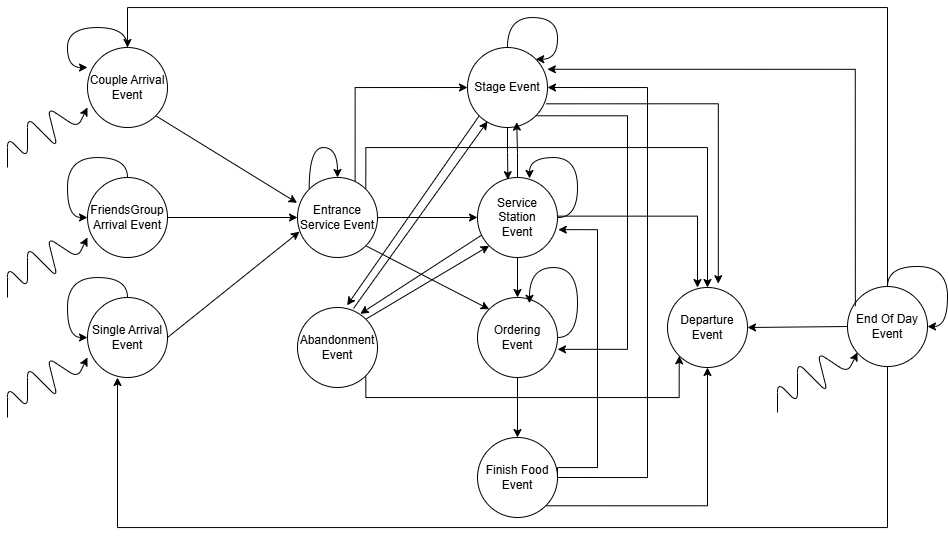

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">


###**תרשים טיפול אירוע הגעת יחיד**



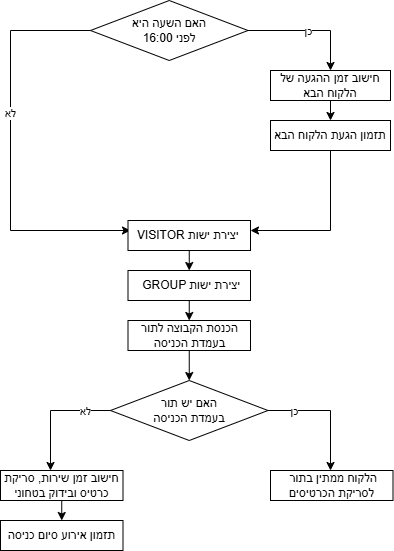

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

###**תרשים טיפול אירוע סיום הזמנת אוכל**

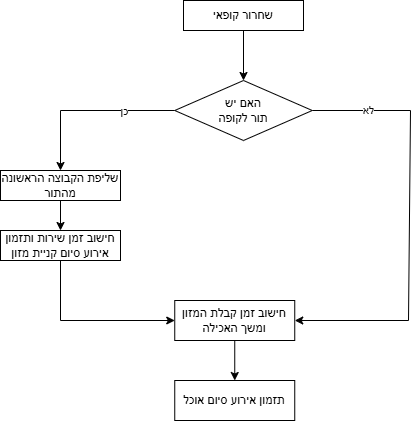

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

###**תרשים טיפול אירוע סיום קניית כרטיסים**

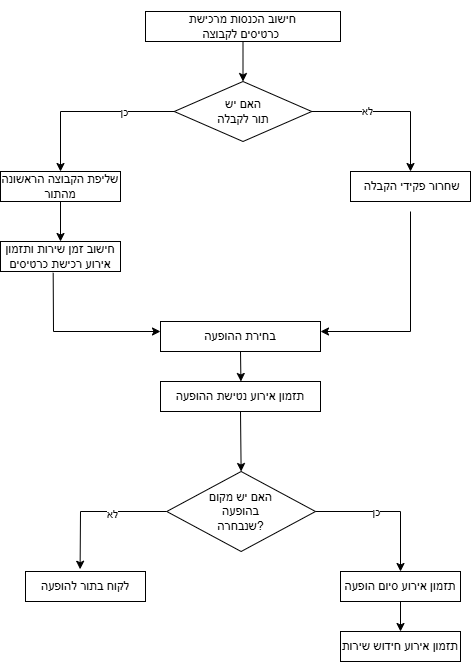

<div dir="rtl" style="text-align: right;">

# **בחירת מדדים**

**מדד שביעות הרצון הממוצע של המבקרים**- הוא מדד מרכזי להערכת איכות חוויית המשתמש בפסטיבל. המדד מושפע ממגוון רחב של גורמים לאורך הביקור, כגון חוויית הצפייה בהופעות, זמן ההמתנה בפעילויות השונות, איכות המזון, עמדות הצילום וציורי הפנים. לכן הוא מספק תמונה כוללת של רמת ההנאה והצלחת הפסטיבל מנקודת מבטם של המבקרים.

**ההכנסות הכוללות של הפסטיבל**- מהוות אינדיקציה ישירה להצלחתו הכלכלית של המודל. ההכנסות נובעות ממכירת כרטיסי כניסה, תוספות לינה, רכישות במתחם המזון, רכישות באוהל המרצ'נדייז ורכישת תמונות בעמדות הצילום. מדד זה מאפשר לבחון האם שינויים תפעוליים וחלופות שונות אכן מייצרים ערך כלכלי לפסטיבל.

שני המדדים יחד נותנים תמונה מאוזנת: **האחד איכותי (שביעות רצון המבקרים)** והשני **כלכלי (הכנסות הפסטיבל)** – ומאפשרים לבחון האם שיפור בחוויית המבקר מתורגם גם לשיפור בביצועים העסקיים של הפסטיבל.

נדגיש את ההצדקה שבשילוב המדדים, שכן שביעות רצון גבוהה יותר עשויה להוביל לשהייה ארוכה יותר בפסטיבל, להשתתפות בפעילויות נוספות ולרכישות רבות יותר של מזון, מוצרים ותמונות. מנגד, התמקדות בהגדלת ההכנסות בלבד עלולה ליצור עומסים ותורים ארוכים אשר יפגעו בחוויית המבקרים. לכן חשוב לבחון את שני המדדים במקביל, על מנת לבחור חלופות המשפרות את ביצועי הפסטיבל תוך שמירה על איזון בין הצלחה כלכלית לבין חוויית מבקר איכותית.

</div>

#מחלקות ישויות

In [ ]:
import random
import math
import heapq
import numpy as np

# This section includes all basic random sampling functions.
# All sampling is based on random numbers from Uniform(0,1),

def sample_u():
    # Generate one random number from a Uniform(0,1) distribution.
    # This function is used as the base random generator for all sampling methods.
    return np.random.uniform(0, 1)


def sample_uniform_discrete(a, b):
    # Sample a discrete integer uniformly from the range [a, b].
    # Example: if a=3 and b=6, the possible values are 3, 4, 5, or 6.
    u = sample_u()

    # Convert the continuous random number into an integer interval.
    # The min() protects from rare floating point cases where the value may become b+1.
    return min(b, a + int(u * (b - a + 1)))


def sample_uniform_continuous(a, b):
    # Sample a continuous value uniformly from the interval [a, b].
    # This uses the inverse transform formula for a continuous uniform distribution.
    u = sample_u()
    return a + (b - a) * u


def sample_exponential_mean(mean):
    # Sample from an exponential distribution using inverse transform sampling.
    # The parameter here is the mean, not lambda.
    # If X ~ Exponential(mean), then X = -mean * ln(1-U).
    u = sample_u()
    return -mean * math.log(1 - u)


def sample_normal_box_muller(mean, std, min_value=0):
    # Sample from a normal distribution using the Box-Muller method.

    # u1 cannot be exactly 0 because ln(0) is undefined.
    # max(..., 1e-10) prevents a mathematical error.
    u1 = max(sample_u(), 1e-10)
    u2 = sample_u()

    # Generate a standard normal value Z ~ N(0,1).
    z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)

    # Convert the standard normal value to N(mean, std^2).
    # Modeling assumption:
    # Negative sampled times are truncated to min_value, because service times
    # and activity durations cannot be negative in the simulation.
    return max(min_value, mean + std * z)


def sample_photo_time():
# Sample the PhotoStation service time using the inverse transform method.
# The service time follows a piecewise probability density function.
# Each interval is sampled using its corresponding inverse CDF.

    u = sample_u()

    # First interval: 1 <= x < 2
    if u < 0.25:
        return math.sqrt(12 * u + 1)

    # Second interval: 2 <= x < 3.
    # The inverse CDF in this interval requires solving a quadratic equation.
    elif u < 0.875:
        a = 1 / 10
        b = 1 / 8
        c = -1 / 15 - u
        discriminant = b**2 - 4 * a * c


        return (-b + math.sqrt(discriminant)) / (2 * a)

    # Third interval: 3 <= x < 4
    else:
        return 3 + 8 * (u - 0.875)


# ============================================================
# Visitor entities
# ============================================================
# This section defines the visitors in the festival.
# The model separates between:
# 1. Guest - one physical person.
# 2. Entity - a simulation unit that may include one or more guests.
#
# For example:
# - Single has 1 guest.
# - Couple has 2 guests.
# - FriendsGroup has 3-6 guests.
#
# This distinction is important because queues are managed by entities,
# while capacity and satisfaction may depend on the number of guests.


class Guest:
    # Guest represents one individual visitor inside an entity.
    # Each guest has an individual satisfaction score and a busy/free status.

    def __init__(self, guest_id, parent_entity, initial_satisfaction=5.0):
        # Create a unique guest ID by combining the parent entity ID
        # with the guest index inside that entity.
        self.guest_id = f"{parent_entity.entity_id}_{guest_id}"

        # Store a reference to the entity this guest belongs to.
        self.parent_entity = parent_entity

        # is_busy indicates whether the guest is currently receiving service.
        # This is mainly used in guest-level stations such as ChargingStation,
        # MerchTent, and BodyArt.
        self.is_busy = False

        # Initial satisfaction is defined by the project as 5.
        self.satisfaction = initial_satisfaction

        # Satisfaction is bounded between 0 and 10 according to the project.
        self.min_satisfaction = 0.0
        self.max_satisfaction = 10.0

    def update_satisfaction(self, delta):
        # Update the guest satisfaction by adding delta.
        # The result is clipped to stay within the allowed range [0,10].
        self.satisfaction = min(
            self.max_satisfaction,
            max(self.min_satisfaction, self.satisfaction + delta)
        )


class Entity:
    # Entity is the base class for all visitor types.
    # It contains shared logic for satisfaction, revenue, queues,
    # activity tracking, and general decision placeholders.
    #
    # Child classes:
    # - FriendsGroup
    # - Couple
    # - Single

    # Default queue abandonment time.
    # Child classes override this value according to the project instructions.
    abandonment_timeout = 20

    # Default satisfaction penalty after abandoning a queue.
    # Child classes override this value according to visitor type.
    satisfaction_penalty = 1.0

    # Ticket and lodging prices according to the project instructions.
    TICKET_PRICE = 500
    TICKET_WITH_LODGING_PRICE = 700
    LODGING_ADD_ON_PRICE = 250

    def __init__(self, entity_id, entity_type, group_size, arrival_time, arrival_day,
                 initial_satisfaction=5.0):
        # Unique ID for the entity in the simulation.
        self.entity_id = entity_id

        # Type of entity: friends, couple, or single.
        self.entity_type = entity_type

        # Number of physical guests in this entity.
        self.group_size = group_size

        # Create Guest objects for all people inside the entity.
        # Each guest receives the same initial satisfaction score.
        self.guests = [
            Guest(i, self, initial_satisfaction)
            for i in range(group_size)
        ]

        # Store arrival information.
        self.arrival_time = arrival_time
        self.arrival_day = arrival_day

        # Entity satisfaction is stored as the average satisfaction of its guests.
        # It is synchronized after guest-level updates.
        self.satisfaction = initial_satisfaction
        self.min_satisfaction = 0.0
        self.max_satisfaction = 10.0

        # Total revenue generated by this entity.
        self.revenue = 0.0

        # Current activity or station where the entity is located.
        self.current_location = None

        # Activity log is used to track when the entity enters and leaves activities.
        self.activity_log = []

        # Queue tracking fields.
        # These fields allow abandonment events to check whether the entity
        # is still waiting in the same queue.
        self.is_in_queue = False
        self.current_queue = None
        self.queue_entry_time = None

        # Overnight and lunch flags.
        # These prevent duplicate lodging and lunch decisions.
        self.stays_overnight = False
        self.has_eaten_day1 = False
        self.has_eaten_day2 = False

    def size(self):
        # Return the number of physical guests in this entity.
        # This is used for capacity calculations in stages.
        return self.group_size

    def free_guests(self):
        # Return all guests in the entity who are not currently being served.
        # This supports stations where guests may be served individually.
        return [guest for guest in self.guests if not guest.is_busy]

    def busy_guests_count(self):
        # Count how many guests from this entity are currently busy.
        return sum(guest.is_busy for guest in self.guests)

    def all_guests_free(self):
        # Check if all guests in the entity have completed the current guest-level service.
        # The entity can only continue to the next activity when all guests are free.
        return self.busy_guests_count() == 0

    def seize_guests(self, amount):
        # Select a given number of free guests and mark them as busy.
        # This is used when a guest-level station starts service for one or more guests.
        selected_guests = self.free_guests()[:amount]

        for guest in selected_guests:
            guest.is_busy = True

        return selected_guests

    def release_guests(self, guests):
        # Mark the given guests as free after their service is completed.
        for guest in guests:
            guest.is_busy = False

    def average_satisfaction(self):
        # Calculate the average satisfaction of all guests in the entity.
        return sum(g.satisfaction for g in self.guests) / self.group_size

    def sync_satisfaction_from_guests(self):
        # Update the entity-level satisfaction to match the average guest satisfaction.
        # Modeling assumption:
        # The entity satisfaction is represented by the average satisfaction
        # of all guests in the entity.
        self.satisfaction = self.average_satisfaction()

    def apply_satisfaction_change_per_guest(self, sample_func):
        # Apply a satisfaction change independently to each guest.
        # sample_func returns the satisfaction change for one guest.
        #
        # Modeling assumption:
        # Satisfaction changes after food or shows are sampled per guest,
        # even when the guests belong to the same entity.
        for guest in self.guests:
            guest.update_satisfaction(sample_func())

        # After updating individual guests, update the entity average.
        self.sync_satisfaction_from_guests()

    def update_satisfaction_after_show(self, genre_value, end_time_hour):
        # Update satisfaction after watching a show.
        # According to the project, each guest has a 0.5 probability
        # of having a good experience.
        def sample():
            if sample_u() < 0.5:
                # Good experience increases satisfaction according to
                # genre value and show ending time.
                return self._calculate_show_bonus(genre_value, end_time_hour)

            # Bad experience decreases satisfaction by 1 point.
            return -1.0

        self.apply_satisfaction_change_per_guest(sample)

    def _calculate_show_bonus(self, genre_value, end_time_hour):
        # Calculate the satisfaction bonus after a good show experience.
        # The formula follows the project instructions:
        # score = ((G - 1) / 2) + ((T - 1) / 19)
        genre_score = (genre_value - 1) / 2
        time_score = (end_time_hour - 1) / 19
        return genre_score + time_score

    def apply_abandonment_penalty(self):
        # Apply a satisfaction penalty when the entity abandons a queue.
        # The penalty size depends on the entity type.
        for guest in self.guests:
            guest.update_satisfaction(-self.satisfaction_penalty)

        # Keep the entity-level satisfaction synchronized.
        self.sync_satisfaction_from_guests()

    def update_satisfaction_after_food(self, bad_food_probability=0.4):
        # Update satisfaction after eating.
        # With probability bad_food_probability, the guest is not satisfied
        # and loses 0.6 satisfaction points.
        def sample():
            if sample_u() < bad_food_probability:
                return -0.6
            return 0.0

        self.apply_satisfaction_change_per_guest(sample)

    def update_satisfaction_after_photo(self):
        # Update satisfaction and revenue after using the PhotoStation.
        # With probability 0.7, the entity is satisfied with the photo.

        if sample_u() < 0.7:
            # If satisfied, all guests in the entity gain 2 satisfaction points.
            for guest in self.guests:
                guest.update_satisfaction(2.0)

            self.sync_satisfaction_from_guests()

            # A printed photo copy is purchased for 30 NIS.
            # Modeling assumption:
            # The 30 NIS payment is charged once per entity, not once per guest.
            amount = 30
            self.add_revenue(amount)
            return amount

        # If the entity is not satisfied, there is a 0.5 probability
        # of decreasing satisfaction by 0.5 points.
        if sample_u() < 0.5:
            for guest in self.guests:
                guest.update_satisfaction(-0.5)

            self.sync_satisfaction_from_guests()

        # No revenue is added if the entity does not buy the photo.
        return 0

    def update_satisfaction_after_body_art(self, art_type):
        # Placeholder method for body art satisfaction logic.
        # In the current implementation, BodyArt updates the guest satisfaction
        # directly inside the BodyArt.finish_service method.
        pass

    def add_revenue(self, amount):
        # Add revenue generated by this entity.
        self.revenue += amount

    def record_regular_ticket_revenue(self):
        # Record revenue for regular entrance tickets.
        # The ticket price is paid by each guest in the entity.
        amount = self.TICKET_PRICE * self.group_size
        self.add_revenue(amount)
        return amount

    def record_ticket_with_lodging_revenue(self):
        # Record revenue for entrance ticket with lodging.
        # This applies mainly to FriendsGroup entities that decide in advance
        # to stay overnight.
        amount = self.TICKET_WITH_LODGING_PRICE * self.group_size
        self.add_revenue(amount)
        return amount

    def record_lodging_addition(self):
        # Record additional lodging payment.
        # This applies to couples that decide at the end of day 1
        # to stay overnight based on their satisfaction.
        amount = self.LODGING_ADD_ON_PRICE * self.group_size
        self.add_revenue(amount)
        return amount

    def buy_merch_for_guest(self, band_shirt_probability=0.3):
        # Simulate merchandise purchases for one guest.
        # This method is called once for each served guest in MerchTent.

        amount = 0

        # Festival shirt: 100 NIS with probability 0.8.
        if sample_u() < 0.8:
            amount += 100

        # Festival hat: 50 NIS with probability 0.4.
        if sample_u() < 0.4:
            amount += 50

        # Flag: 40 NIS with probability 0.9.
        if sample_u() < 0.9:
            amount += 40

        # Band shirt: 200 NIS with configurable probability.
        # In one alternative, this probability can be increased.
        if sample_u() < band_shirt_probability:
            amount += 200

        # Add the guest's merch purchase to the entity revenue.
        self.add_revenue(amount)
        return amount

    def buy_food(self, restaurant):
        # Calculate and record food revenue based on the selected restaurant.

        if restaurant == "pizza":
            if self.entity_type.lower() == "single":
                # Single visitors buy one personal pizza.
                amount = 40
            else:
                # Groups and couples buy family trays.
                # Each tray is enough for up to 3 people.
                # The formula rounds up group_size / 3.
                trays = (self.group_size + 2) // 3
                amount = 100 * trays

        elif restaurant == "burger":
            # Burger meal price is per guest.
            amount = 100 * self.group_size

        elif restaurant == "asian":
            # Asian meal price is per guest.
            amount = 65 * self.group_size

        else:

            amount = 0

        self.add_revenue(amount)
        return amount

    def start_activity(self, activity, current_time):
        # Mark the entity as currently located in the given activity.
        self.current_location = activity

        # Add an entry event to the activity log.
        self._log_activity("enter", activity, current_time)

    def end_activity(self, current_time, reason="finished"):
        # Add a leave event to the activity log.
        self._log_activity("leave", self.current_location, current_time, reason)

        # Clear the current location after leaving the activity.
        self.current_location = None

    def _log_activity(self, event_type, activity, time, reason=None):
        # Save an activity log record for tracking and debugging.
        entry = {"event": event_type, "activity": activity, "time": time}

        # Add a reason only when it is provided.
        if reason:
            entry["reason"] = reason

        self.activity_log.append(entry)

    def enter_queue(self, queue_name, current_time):
        # Mark the entity as waiting in a queue.
        # This information is used later by abandonment events.
        self.is_in_queue = True
        self.current_queue = queue_name
        self.queue_entry_time = current_time

    def leave_queue(self):
        # Clear queue status after the entity leaves or starts service.
        self.is_in_queue = False
        self.current_queue = None
        self.queue_entry_time = None

    def decide_overnight(self):
        # Default overnight behavior.
        # Most entity types override this method if needed.
        self.stays_overnight = False
        return self.stays_overnight

    def next_activity(self, queue_lengths=None):
        # Default next activity behavior.
        # Each child class defines its own activity selection logic.
        return None


class FriendsGroup(Entity):
    # FriendsGroup represents a group of 3-6 friends.
    # Friends arrive only on day 1 and may stay overnight.
    # They want to visit all shows and all stations.

    # Friends are less patient and abandon queues after 15 minutes.
    abandonment_timeout = 15

    # Friends lose 2 satisfaction points after abandoning a queue.
    satisfaction_penalty = 2.0

    def __init__(self, entity_id, arrival_time, initial_satisfaction=5.0):
        # Sample the group size from a discrete uniform distribution [3,6].
        group_size = sample_uniform_discrete(3, 6)

        # Initialize the base Entity fields.
        # FriendsGroup always arrives on day 1 according to the project.
        super().__init__(
            entity_id=entity_id,
            entity_type="friends",
            group_size=group_size,
            arrival_time=arrival_time,
            arrival_day=1,
            initial_satisfaction=initial_satisfaction
        )

        # Decide whether the group stays overnight.
        # According to the project, this happens with probability 0.7.
        self.stays_overnight = sample_u() < 0.7

        # Ticket revenue is recorded immediately when the entity is created.
        if self.stays_overnight:
            self.record_ticket_with_lodging_revenue()
        else:
            self.record_regular_ticket_revenue()

        # Friends want to attend one show of each type.
        self.required_shows = {"MainStage", "SideStage", "DJStage"}

        # Friends also want to visit all service stations.
        self.required_stations = {"PhotoStation", "ChargingStation", "MerchTent", "BodyArt"}

        # These sets track which activities were already completed.
        self.visited_shows = set()
        self.visited_stations = set()

    def mark_show_visited(self, show_name):
        # Mark a show as completed by the group.
        self.visited_shows.add(show_name)

    def mark_station_visited(self, station_name):
        # Mark a station as completed by the group.
        self.visited_stations.add(station_name)

    def remaining_shows(self):
        # Return the shows that the group still needs to visit.
        return self.required_shows - self.visited_shows

    def remaining_stations(self):
        # Return the stations that the group still needs to visit.
        return self.required_stations - self.visited_stations

    def next_activity(self, queue_lengths=None):
        # Choose the next activity for the friends group.
        # The group first completes all required shows.
        # After that, it completes all required stations.

        queue_lengths = queue_lengths or {}

        # Select among remaining shows first.
        shows_left = list(self.remaining_shows())
        if shows_left:
            # Modeling assumption:
            # When multiple shows remain, the group chooses the show
            # with the shortest current queue.
            return min(shows_left, key=lambda x: queue_lengths.get(x, 0))

        # After all shows are completed, select among remaining stations.
        stations_left = list(self.remaining_stations())
        if stations_left:
            # Modeling assumption:
            # When multiple stations remain, the group chooses the station
            # with the shortest current queue.
            return min(stations_left, key=lambda x: queue_lengths.get(x, 0))

        # If there are no remaining activities, the entity can leave the festival.
        return None


class Couple(Entity):
    # Couple represents two visitors arriving together.
    # Couples alternate between shows and stations.
    # They do not attend the DJStage.

    # Couples abandon queues after 20 minutes.
    abandonment_timeout = 20

    # Couples lose 1.5 satisfaction points after abandoning a queue.
    satisfaction_penalty = 1.5

    def __init__(self, entity_id, arrival_time, arrival_day, initial_satisfaction=5.0):
        # Initialize a couple as an entity with exactly 2 guests.
        super().__init__(
            entity_id=entity_id,
            entity_type="couple",
            group_size=2,
            arrival_time=arrival_time,
            arrival_day=arrival_day,
            initial_satisfaction=initial_satisfaction
        )

        # Couples initially buy regular tickets.
        self.record_regular_ticket_revenue()

        # Couples start with a show, then alternate between show and station.
        self.next_is_show = True

        # Couples only like MainStage and SideStage.
        self.eligible_shows = {"MainStage", "SideStage"}

        # Couples may visit any non-stage service station.
        self.eligible_stations = {"PhotoStation", "ChargingStation", "MerchTent", "BodyArt"}

    def decide_overnight(self):
        # Decide whether the couple stays overnight.
        # According to the project, a couple stays only if:
        # 1. It arrived on day 1.
        # 2. Its satisfaction at the end of the day is above 7.

        if self.arrival_day == 1 and self.average_satisfaction() > 7 and not self.stays_overnight:
            self.stays_overnight = True

            # If the couple decides to stay overnight, it pays the lodging add-on.
            self.record_lodging_addition()

        elif not (self.arrival_day == 1 and self.average_satisfaction() > 7):
            self.stays_overnight = False

        return self.stays_overnight

    def switch_next_activity_type(self):
        # Switch the next activity type.
        # If the next activity was a show, the next one will be a station, and vice versa.
        self.next_is_show = not self.next_is_show

    def next_activity(self, queue_lengths=None):
        # Choose the next activity for a couple.
        # The choice is random with equal probability among eligible activities
        # of the current activity type.

        if self.next_is_show:
            shows = list(self.eligible_shows)

            # Choose one eligible show uniformly.
            return shows[int(sample_u() * len(shows))]

        stations = list(self.eligible_stations)

        # Choose one eligible station uniformly.
        return stations[int(sample_u() * len(stations))]

    def mark_activity_completed(self):
        # After completing an activity, switch to the other activity type.
        self.switch_next_activity_type()

    def skip_current_activity(self):
        # If a couple abandons a queue, it still switches to the next activity type.
        # Modeling assumption:
        # Abandoning a queue counts as skipping the current activity type.
        self.switch_next_activity_type()


class Single(Entity):
    # Single represents one visitor.
    # Single visitors first go to the MerchTent, then attend a fixed number of shows.
    # They do not stay overnight.

    # Singles abandon queues after 20 minutes.
    abandonment_timeout = 20

    # Singles lose 1 satisfaction point after abandoning a queue.
    satisfaction_penalty = 1.0

    def __init__(self, entity_id, arrival_time, arrival_day, initial_satisfaction=5.0):
        # Initialize a single visitor as an entity with one guest.
        super().__init__(
            entity_id=entity_id,
            entity_type="single",
            group_size=1,
            arrival_time=arrival_time,
            arrival_day=arrival_day,
            initial_satisfaction=initial_satisfaction
        )

        # Single visitors buy regular tickets only.
        self.record_regular_ticket_revenue()

        # Track whether the visitor already completed the MerchTent activity.
        self.visited_merch = False

        # Required show visits according to the project:
        # 2 MainStage shows, 2 SideStage shows, and 1 DJStage visit.
        self.remaining_show_visits = {
            "MainStage": 2,
            "SideStage": 2,
            "DJStage": 1
        }

    def decide_overnight(self):
        # Single visitors do not stay overnight.
        self.stays_overnight = False
        return False

    def next_activity(self, queue_lengths=None):
        # Choose the next activity for a single visitor.
        # The first activity must be the MerchTent.
        queue_lengths = queue_lengths or {}

        if not self.visited_merch:
            return "MerchTent"

        # Build a list of shows that still need to be visited.
        available_shows = [
            s for s, c in self.remaining_show_visits.items()
            if c > 0
        ]

        if available_shows:
            # Modeling assumption:
            # After visiting the MerchTent, a single visitor chooses
            # the required show with the shortest current queue.
            return min(available_shows, key=lambda s: queue_lengths.get(s, 0))

        # If no required shows remain, the visitor can leave.
        return None

    def mark_activity_completed(self):
        # Mark the MerchTent as completed.
        # This method is only used for the first required activity.
        if not self.visited_merch:
            self.visited_merch = True

    def mark_show_completed(self, stage_name):
        # Reduce the number of remaining visits for a completed show type.
        if stage_name in self.remaining_show_visits and self.remaining_show_visits[stage_name] > 0:
            self.remaining_show_visits[stage_name] -= 1

    def skip_current_activity(self):
        # If the single visitor abandons the MerchTent queue,
        # the model allows the visitor to continue to shows.
        # Modeling assumption:
        # Abandoning the MerchTent queue counts as skipping the MerchTent activity.
        if not self.visited_merch:
            self.visited_merch = True

#מחלקת תור

In [ ]:
# This section contains the general queue mechanism used by stations.
# QueueServer represents a queue with one or more identical servers.
# It tracks waiting time, queue length, abandonment, and utilization.


class QueueServer:
    # QueueServer is a generic multi-server queue.
    # It is used by stations where the whole entity receives service together,
    # such as EntranceStation, PhotoStation, and each FoodCourt cashier.

    def __init__(self, name, num_servers, start_time=540, allow_abandonment=True):
        # Name of the queue system or station.
        self.name = name

        # Number of parallel servers working in this queue.
        # For example, 5 entrance clerks or 1 cashier.
        self.num_servers = num_servers

        # Indicates whether entities are allowed to abandon this queue.
        # EntranceStation uses False because visitors do not abandon the entrance.
        self.allow_abandonment = allow_abandonment

        # servers[i] stores the entity currently served by server i.
        # None means that the server is idle.
        self.servers = [None] * num_servers

        # The queue stores tuples of (entity, queue_entry_time).
        # This allows wait time calculation when the entity starts service.
        self.queue = []

        # Simulation time when this queue starts operating.
        self.start_time = start_time

        # Last time the queue length was updated.
        # Used to calculate time-weighted average queue length.
        self.last_queue_change_time = start_time

        # Total waiting time accumulated by all served entities.
        self.total_wait_time = 0.0

        # Number of entities that started service.
        self.num_served = 0

        # Number of entities that abandoned this queue.
        self.num_abandoned = 0

        # Number of physical people who abandoned this queue.
        # This may differ from num_abandoned because an entity can include several guests.
        self.num_abandoned_people = 0

        # Integral of queue length over time.
        # Later divided by total time to calculate average queue length.
        self.queue_length_time = 0.0

        # Total busy time per server.
        # Used to calculate server utilization.
        self.server_busy_time = [0.0] * num_servers

        # Last time each server status was updated.
        self.last_server_change_time = [start_time] * num_servers

    def add_to_queue(self, entity, current_time):
        # Add an entity to the queue at the current simulation time.

        # Update queue length statistics before changing the queue.
        self._update_queue_length_metric(current_time)

        # Store the entity together with the time it entered the queue.
        self.queue.append((entity, current_time))

        # Update the entity queue status.
        # This is later used by QueueAbandonmentEvent.
        entity.enter_queue(self.name, current_time)

    def remove_from_queue(self, entity, current_time, apply_penalty=True):
        # Remove an entity from the queue.
        # This is used mainly when an entity abandons a queue,
        # or when the simulation clears all queues at the end of the day.

        # Update queue length statistics before removing the entity.
        self._update_queue_length_metric(current_time)

        # Search for the entity in the queue by entity_id.
        for i, (queued_entity, enter_time) in enumerate(self.queue):
            if queued_entity.entity_id == entity.entity_id:
                # Remove the entity from the queue.
                self.queue.pop(i)

                # Clear the entity queue state.
                queued_entity.leave_queue()

                # If this removal represents abandonment, apply penalty and update counters.
                if self.allow_abandonment and apply_penalty:
                    queued_entity.apply_abandonment_penalty()
                    self.num_abandoned += 1
                    self.num_abandoned_people += queued_entity.size()

                return True

        # Return False if the entity was not found in the queue.
        return False

    def release_entity_from_servers(self, entity, current_time):
        # Remove an entity from service if it is currently being served.
        # This is called exclusively at the end of the day by remove_entity_from_all_places
        # to free servers that were still busy when the festival closed at 20:00.

        for server_id, server_entity in enumerate(self.servers):
            if server_entity is not None and server_entity.entity_id == entity.entity_id:
                # Update busy time before releasing the server.
                self._update_server_busy_metric(server_id, current_time)

                # Mark the server as idle.
                self.servers[server_id] = None

    def pop_next(self, current_time):
        # Take the first entity from the queue and move it toward service.
        # The queue discipline here is FIFO.

        if not self.queue:
            return None

        # Update queue length statistics before removing the first entity.
        self._update_queue_length_metric(current_time)

        # Remove the first entity in line.
        entity, enter_time = self.queue.pop(0)

        # Clear the entity queue state because it is no longer waiting.
        entity.leave_queue()

        # Add this entity's waiting time to the total waiting time.
        self.total_wait_time += current_time - enter_time

        # Count this entity as served once it starts service.
        self.num_served += 1

        return entity

    def has_free_server(self):
        # Check whether at least one server is currently idle.
        return any(server is None for server in self.servers)

    def get_free_server_index(self):
        # Return the index of the first available server.
        for i, server in enumerate(self.servers):
            if server is None:
                return i

        # Return None if all servers are busy.
        return None

    def assign_to_server(self, server_id, entity, current_time):
        # Assign an entity to a specific server.

        # Update server busy-time statistics before changing its state.
        self._update_server_busy_metric(server_id, current_time)

        # Store the entity as the content of the selected server.
        self.servers[server_id] = entity

    def finish_service(self, server_id, current_time):
        # Finish the service currently running on a specific server.

        # If the server is already idle, there is no entity to return.
        if self.servers[server_id] is None:
            return None

        # Update busy-time statistics before releasing the server.
        self._update_server_busy_metric(server_id, current_time)

        # Save the served entity before clearing the server.
        entity = self.servers[server_id]

        # Mark the server as idle.
        self.servers[server_id] = None

        return entity

    def try_start_service(self, current_time):
        # Start service for as many entities as possible.
        # Service starts only while there is both:
        # 1. at least one free server
        # 2. at least one entity waiting in the queue

        started = []

        while self.has_free_server() and self.queue:
            # Find an available server.
            server_id = self.get_free_server_index()

            # Take the next entity from the queue.
            entity = self.pop_next(current_time)

            if entity is not None:
                # Assign the entity to the server.
                self.assign_to_server(server_id, entity, current_time)

               # Store the started service so the station can schedule
               # a future EndServiceEvent for this entity.
                started.append((entity, server_id))

        return started

    def size(self):
        # Return the current number of entities waiting in the queue.
        return len(self.queue)

    def _update_queue_length_metric(self, current_time):
        # Update the time-weighted queue length metric.
        #
        # The average queue length is calculated as:
        # integral(queue length over time) / total simulation time.

        # Time passed since the last queue length update.
        dt = current_time - self.last_queue_change_time

        if dt > 0:
            # Add the current queue length multiplied by the time duration.
            self.queue_length_time += len(self.queue) * dt

        # Store the current time as the latest queue length update time.
        self.last_queue_change_time = current_time

    def _update_server_busy_metric(self, server_id, current_time):
        # Update the busy time for one server.
        #
        # This method must be called before changing the server status,
        # so the previous status is measured correctly.

        # Time passed since the last status update for this server.
        dt = current_time - self.last_server_change_time[server_id]

        # Add busy time only if the server was busy during this interval.
        if dt > 0 and self.servers[server_id] is not None:
            self.server_busy_time[server_id] += dt

        # Store the current time as the latest update time for this server.
        self.last_server_change_time[server_id] = current_time

    def get_statistics(self, current_time):
        # Calculate performance statistics for this queue system.

        # Update queue length until the current simulation time.
        self._update_queue_length_metric(current_time)

        # Update busy time for all servers until the current simulation time.
        for server_id in range(self.num_servers):
            self._update_server_busy_metric(server_id, current_time)

        # Total time since the station started operating.
        # max(..., 1) prevents division by zero.
        total_time = max(current_time - self.start_time, 1)

        # Total busy time across all servers.
        total_busy = sum(self.server_busy_time)

        # Maximum possible busy time across all servers.
        capacity = self.num_servers * total_time

        return {
            # Station name.
            "station_name": self.name,

            # Average waiting time among entities that actually started service.
            "avg_wait_time": self.total_wait_time / self.num_served if self.num_served > 0 else 0,

            # Time-weighted average queue length.
            "avg_queue_length": self.queue_length_time / total_time,

            # Server utilization = total busy time / total available server time.
            "utilization": total_busy / capacity if capacity > 0 else 0,

            # Number of entities that started service.
            "served_entities": self.num_served,

            # Number of entities that abandoned the queue.
            "abandoned_entities": self.num_abandoned,

            # Number of physical people who abandoned the queue.
            "abandoned_people": self.num_abandoned_people,

            # Current number of entities waiting in the queue.
            "current_queue_length": len(self.queue)
        }

#מחלקות תחנות

In [ ]:
# ServiceStation is a generic wrapper around QueueServer.
# It represents stations where the whole entity receives service together.
class ServiceStation:
    def __init__(self, name, num_servers, start_time=540, allow_abandonment=True):
        # Store the station name.
        self.name = name
        # Use QueueServer to manage the queue, servers, waiting times, abandonment, and statistics.
        self.queue_system = QueueServer(name, num_servers, start_time, allow_abandonment)

    def add_entity_to_queue(self, entity, current_time):
        # Add the entity to the station queue through the internal QueueServer.
        self.queue_system.add_to_queue(entity, current_time)

    def sample_service_time(self, entity=None):
        # Abstract method.
        # Each specific station must define its own service time distribution.
        raise NotImplementedError

    def apply_service_result(self, entity, server_id=None, current_time=None):
        # Optional hook for stations that need to update satisfaction or revenue after service.
        # Stations that do not need a result update can leave this method empty.
        pass

    def try_start_service(self, current_time):
        # Try to start service for all entities that can be served now.
        started_services = []
        for entity, server_id in self.queue_system.try_start_service(current_time):
            # Mark the entity as being inside this station.
            entity.start_activity(self.name, current_time)
            # Sample the service duration according to the specific station.
            service_time = self.sample_service_time(entity)
            # Return service details so the simulator can schedule an end-service event.
            started_services.append({
                "station": self,
                "entity": entity,
                "server_id": server_id,
                "service_time": service_time,
                "finish_time": current_time + service_time
            })
        return started_services

    def finish_service(self, server_id, current_time):
        # Finish service on the selected server and get the served entity.
        entity = self.queue_system.finish_service(server_id, current_time)
        if entity is None:
            return None
        # Apply station-specific effects, such as satisfaction or revenue updates.
        self.apply_service_result(entity, server_id, current_time)
        # Mark the entity as leaving the station.
        entity.end_activity(current_time, reason="finished")
        return entity

    def remove_from_queue(self, entity, current_time, apply_penalty=True):
        # Remove an entity from this station queue.
        # This is mainly used for queue abandonment and end-of-day clearing.
        return self.queue_system.remove_from_queue(entity, current_time, apply_penalty)

    def release_entity_from_servers(self, entity, current_time):
        # Release an entity from service if it is currently being served.
        # This is used when clearing the system at the end of the day.
        self.queue_system.release_entity_from_servers(entity, current_time)

    def size(self):
        # Return the current number of entities waiting in this station queue.
        return self.queue_system.size()

    def get_statistics(self, current_time):
        # Return the queue statistics calculated by the internal QueueServer.
        # This method is called at the end of the simulation
        # to collect performance metrics for the final report.
        return self.queue_system.get_statistics(current_time)


# EntranceStation models the festival entrance.
# Visitors pass ticket scanning and security check before entering the festival.
class EntranceStation(ServiceStation):
    def __init__(self, start_time=540):
        # The entrance has 5 servers and does not allow abandonment.
        super().__init__("EntranceStation", 5, start_time, allow_abandonment=False)

    def sample_service_time(self, entity=None):
        # Entrance service time is ticket scanning time plus security check time.
        # Ticket scanning: Uniform(1.5, 3).
        # Security check: Exponential with mean 2.
        return sample_uniform_continuous(1.5, 3) + sample_exponential_mean(2)


# PhotoStation models the photo booth area.
# The whole entity is served together.
class PhotoStation(ServiceStation):
    def __init__(self, start_time=540, config=None):
        config = config or {}
        # Base case has 3 photo stations.
        # In the ADD_PHOTO_AND_BODYART alternative, one more photo station is added.
        num_servers = 4 if config.get("ADD_PHOTO_AND_BODYART", False) else 3
        super().__init__("PhotoStation", num_servers, start_time, allow_abandonment=True)

    def sample_service_time(self, entity=None):
        # Sample photo service time from the piecewise distribution.
        return sample_photo_time()

    def apply_service_result(self, entity, server_id=None, current_time=None):
        # After the photo service, update satisfaction and possible photo revenue.
        entity.update_satisfaction_after_photo()


# GuestServiceStation is used for stations where guests are served individually.
# The entity waits as a group, but service is performed per guest.
# The entity can continue only after all of its guests finish the activity.
class GuestServiceStation:
    def __init__(self, name, num_servers, start_time=540, allow_abandonment=True):
        # Store the station name.
        self.name = name
        # Number of parallel servers, such as chargers, cashiers, or artists.
        self.num_servers = num_servers
        # Indicates whether entities can abandon this station queue.
        self.allow_abandonment = allow_abandonment

        # Each server stores the guest currently being served.
        # None means the server is idle.
        self.servers = [None] * num_servers
        # Queue stores entities, not individual guests.
        self.queue = []

        # Station start time.
        self.start_time = start_time
        # Last time the queue length was updated.
        self.last_queue_change_time = start_time
        # Time-weighted queue length accumulator.
        self.queue_length_time = 0.0

        # Total waiting time is counted per guest that starts service.
        self.total_wait_time = 0.0
        # Number of individual guests served.
        self.num_served_guests = 0
        # Number of entities that abandoned the queue.
        self.num_abandoned_entities = 0
        # Number of physical people that abandoned the queue.
        self.num_abandoned_people = 0

        # Busy time per server, used for utilization.
        self.server_busy_time = [0.0] * num_servers
        # Last update time per server.
        self.last_server_change_time = [start_time] * num_servers

    def add_entity_to_queue(self, entity, current_time):
        # Update queue-length statistics before adding the entity.
        self._update_queue_length_metric(current_time)
        # Add the entity to the guest-level station queue.
        self.queue.append((entity, current_time))
        # Mark the entity as waiting in this queue.
        entity.enter_queue(self.name, current_time)

    def sample_service_time(self, entity=None, guest=None):
        # Abstract method.
        # Each specific guest-level station defines its own service time.
        raise NotImplementedError

    def apply_guest_service_result(self, entity, guest, current_time=None):
        # Optional hook for applying the result of a guest-level service.
        # For example, MerchTent updates revenue and BodyArt updates satisfaction.
        pass

    def try_start_service(self, current_time):
        # Start service for as many individual guests as possible.
        started_services = []
        while self.has_free_server() and self.queue:
            # Find an available server.
            server_id = self.get_free_server_index()
            # Get the next available guest from the first entity that has a free guest.
            entity, guest, enter_time = self._get_next_guest(current_time)
            if entity is None:
                break

            # Assign this guest to the selected server.
            self._assign_guest_to_server(server_id, entity, guest, current_time)

            # Start the activity for the entity only once.
            if entity.current_location != self.name:
                entity.start_activity(self.name, current_time)

            # Sample the service time for this guest.
            service_time = self.sample_service_time(entity, guest)

            # Return service details so the simulator can schedule the end event.
            started_services.append({
                "station": self,
                "entity": entity,
                "guest": guest,
                "server_id": server_id,
                "service_time": service_time,
                "finish_time": current_time + service_time
            })
        return started_services

    def _get_next_guest(self, current_time):
        # Search the queue for the first entity with at least one free guest.
        for i, (entity, enter_time) in enumerate(self.queue):
            free_guests = entity.free_guests()
            if free_guests:
                # Take one free guest from the entity and mark the guest as busy.
                guest = entity.seize_guests(1)[0]
                # Waiting time is counted for each guest that starts service.
                self.total_wait_time += current_time - enter_time
                self.num_served_guests += 1

                # If all guests from this entity have started service,
                # remove the entity from the waiting queue.
                if len(entity.free_guests()) == 0:
                    self._update_queue_length_metric(current_time)
                    self.queue.pop(i)
                    entity.leave_queue()

                return entity, guest, enter_time

        # No available guest was found.
        return None, None, None

    def finish_service(self, server_id, current_time):
        # Finish service for the guest currently assigned to this server.
        server_content = self.servers[server_id]
        if server_content is None:
            return None

        # Update server busy-time statistics before releasing the server.
        self._update_server_busy_metric(server_id, current_time)
        entity = server_content["entity"]
        guest = server_content["guest"]

        # Apply station-specific result for this guest.
        self.apply_guest_service_result(entity, guest, current_time)

        # Mark the guest as free again.
        entity.release_guests([guest])
        # Release the server.
        self.servers[server_id] = None

        # The entity can continue only when all guests are free
        # and the entity is no longer waiting in the station queue.
        entity_ready_to_continue = (
            entity.all_guests_free()
            and not entity.is_in_queue
        )

        if entity_ready_to_continue:
            # End the activity only after the last guest finishes.
            entity.end_activity(current_time, reason="finished")

        # Return information to the event handler.
        return {
            "entity": entity,
            "guest": guest,
            "entity_ready_to_continue": entity_ready_to_continue
        }

    def remove_from_queue(self, entity, current_time, apply_penalty=True):
        # Remove an entity from the queue.
        # An entity cannot abandon this station if some of its guests are already being served.
        if not entity.all_guests_free():
            return False

        # Update queue-length statistics before removing from the queue.
        self._update_queue_length_metric(current_time)

        # Search for the entity in the queue.
        for i, (queued_entity, enter_time) in enumerate(self.queue):
            if queued_entity.entity_id == entity.entity_id:
                self.queue.pop(i)
                queued_entity.leave_queue()

                # If this is a real abandonment, apply penalty and update counters.
                if self.allow_abandonment and apply_penalty:
                    queued_entity.apply_abandonment_penalty()
                    self.num_abandoned_entities += 1
                    self.num_abandoned_people += queued_entity.size()

                return True

        # Entity was not found in the queue.
        return False

    def release_entity_from_servers(self, entity, current_time):
        # Release all guests of this entity from servers.
        # This is called exclusively at the end of the day by remove_entity_from_all_places
        # to free servers that were still busy when the festival closed at 20:00.
        for server_id, content in enumerate(self.servers):
            if content is not None and content["entity"].entity_id == entity.entity_id:
                self._update_server_busy_metric(server_id, current_time)
                guest = content["guest"]
                entity.release_guests([guest])
                self.servers[server_id] = None

    def has_free_server(self):
        # Check if at least one server is idle.
        return any(server is None for server in self.servers)

    def get_free_server_index(self):
        # Return the first available server index.
        for i, server in enumerate(self.servers):
            if server is None:
                return i
        return None

    def _assign_guest_to_server(self, server_id, entity, guest, current_time):
        # Update server statistics before assigning a new guest.
        self._update_server_busy_metric(server_id, current_time)
        # Store both the entity and the specific guest being served.
        self.servers[server_id] = {
            "entity": entity,
            "guest": guest
        }

    def _update_queue_length_metric(self, current_time):
        # Update the time-weighted average queue length accumulator.
        dt = current_time - self.last_queue_change_time
        if dt > 0:
            self.queue_length_time += len(self.queue) * dt
        self.last_queue_change_time = current_time

    def _update_server_busy_metric(self, server_id, current_time):
        # Update busy time for a specific server.
        dt = current_time - self.last_server_change_time[server_id]
        if dt > 0 and self.servers[server_id] is not None:
            self.server_busy_time[server_id] += dt
        self.last_server_change_time[server_id] = current_time

    def size(self):
        # Return the number of entities waiting in the queue.
        return len(self.queue)

    def get_statistics(self, current_time):
        # Update all time-dependent statistics before returning results.
        self._update_queue_length_metric(current_time)
        for server_id in range(self.num_servers):
            self._update_server_busy_metric(server_id, current_time)

        # Total active time of this station.
        total_time = max(current_time - self.start_time, 1)
        # Total busy time over all servers.
        total_busy = sum(self.server_busy_time)
        # Maximum possible service time over all servers.
        capacity = self.num_servers * total_time

        return {
            "station_name": self.name,
            "avg_guest_wait_time": self.total_wait_time / self.num_served_guests
                                   if self.num_served_guests > 0 else 0,
            "avg_queue_length": self.queue_length_time / total_time,
            "utilization": total_busy / capacity if capacity > 0 else 0,
            "served_guests": self.num_served_guests,
            "abandoned_entities": self.num_abandoned_entities,
            "abandoned_people": self.num_abandoned_people,
            "current_queue_length": len(self.queue)
        }


# MerchTent is a guest-level station.
# Each guest buys merchandise independently.
class MerchTent(GuestServiceStation):
    def __init__(self, band_shirt_probability=0.3, start_time=540, config=None):
        config = config or {}
        # In the POPULAR_MAINSTREAM alternative, the probability of buying a band shirt increases.
        if config.get("POPULAR_MAINSTREAM", False):
            band_shirt_probability = 0.8

        # The merch tent has 7 cashiers.
        super().__init__("MerchTent", 7, start_time, allow_abandonment=True)
        self.band_shirt_probability = band_shirt_probability

    def sample_service_time(self, entity=None, guest=None):
        # Merchandise purchase duration follows Uniform(2,6).
        return sample_uniform_continuous(2, 6)

    def apply_guest_service_result(self, entity, guest, current_time=None):
        # After service, generate merchandise purchases for this guest.
        entity.buy_merch_for_guest(self.band_shirt_probability)


# ChargingStation is a guest-level station.
# Each guest has a personal battery level and charging time.
class ChargingStation(GuestServiceStation):
    def __init__(self, num_chargers=150, start_time=540):
        # The charging station has 150 chargers.
        super().__init__("ChargingStation", num_chargers, start_time, allow_abandonment=True)

    def sample_battery_level(self):
        # Battery level follows a normal distribution with mean 40 and standard deviation 15.
        # The value is capped at 99.9 to avoid division by zero in alpha calculation.
        return min(99.9, sample_normal_box_muller(40, 15, min_value=0))

    def sample_charging_time(self, battery_level):
        # Charging time depends on the sampled battery level b.
        # alpha = 100 / (100 - b), according to the project instructions.
        alpha = 100 / (100 - battery_level)
        u = sample_u()
        # Inverse transform sampling for the charging time distribution.
        return 40 * (1 - (1 - u) ** (1 / alpha))

    def sample_service_time(self, entity=None, guest=None):
        # Sample the guest's battery level.
        battery_level = self.sample_battery_level()
        if guest is not None:
            # Store the sampled battery level for this guest.
            guest.battery_level = battery_level
        # Charging service time is calculated from the battery level.
        return self.sample_charging_time(battery_level)


# BodyArt is a guest-level station.
# Each guest chooses one art type and is served by one artist.
class BodyArt(GuestServiceStation):
    def __init__(self, num_artists=2, start_time=540, config=None):
        config = config or {}
        # Base case has 2 artists.
        # In the ADD_PHOTO_AND_BODYART alternative, one more artist is added.
        num_artists = 3 if config.get("ADD_PHOTO_AND_BODYART", False) else num_artists

        super().__init__("BodyArt", num_artists, start_time, allow_abandonment=True)
        # Count how many drawings each artist has completed.
        self.drawings_per_artist = [0] * num_artists
        # Store the next time each artist is available.
        self.artist_ready_times = [start_time] * num_artists
        # Store the current art type handled by each artist.
        self.active_art_types = [None] * num_artists

    def sample_art_type(self):
        # Sample the selected art type.
        # Glitter probability: 0.3.
        # Neon probability: 0.3.
        # Henna probability: 0.4.
        u = sample_u()
        if u < 0.3:
            return "glitter"
        elif u < 0.6:
            return "neon"
        else:
            return "henna"

    def sample_service_time_by_art_type(self, art_type):
        # Sample service time according to the selected art type.
        if art_type == "glitter":
            # Glitter duration follows Normal(15,3).
            return sample_normal_box_muller(15, 3, min_value=0)
        if art_type == "neon":
            # Neon duration follows Exponential with mean 12.
            return sample_exponential_mean(12)
        if art_type == "henna":
            # Henna duration follows Uniform(17,22).
            return sample_uniform_continuous(17, 22)
        return 0

    def _get_available_artist(self, current_time):
        # Return an artist only if the server is free
        # and the artist is not currently on break.
        for server_id, server in enumerate(self.servers):
            if server is None and current_time >= self.artist_ready_times[server_id]:
                return server_id
        return None

    def try_start_service(self, current_time):
        # Try to start body-art services while there are waiting entities
        # and at least one artist is available.
        started_services = []
        while self.queue:
            server_id = self._get_available_artist(current_time)
            if server_id is None:
                break

            entity, guest, enter_time = self._get_next_guest(current_time)
            if entity is None:
                break

            self._assign_guest_to_server(server_id, entity, guest, current_time)

            if entity.current_location != self.name:
                entity.start_activity(self.name, current_time)

            # Choose the art type at the beginning of the service.
            art_type = self.sample_art_type()
            self.active_art_types[server_id] = art_type
            # Sample duration according to this art type.
            service_time = self.sample_service_time_by_art_type(art_type)

            started_services.append({
                "station": self,
                "entity": entity,
                "guest": guest,
                "server_id": server_id,
                "service_time": service_time,
                "finish_time": current_time + service_time
            })

        return started_services

    def finish_service(self, server_id, current_time):
        # Finish the body-art service for one guest.
        server_content = self.servers[server_id]
        if server_content is None:
            return None

        self._update_server_busy_metric(server_id, current_time)

        entity = server_content["entity"]
        guest = server_content["guest"]
        art_type = self.active_art_types[server_id]

        # Satisfaction increase depends on the art type and satisfaction probability.
        delta = 0.0
        if art_type == "glitter" and sample_u() < 0.7:
            delta = 0.8
        elif art_type == "neon" and sample_u() < 0.6:
            delta = 1.2
        elif art_type == "henna" and sample_u() < 0.8:
            delta = 0.7

        # Update only the served guest, then synchronize entity satisfaction.
        guest.update_satisfaction(delta)
        entity.sync_satisfaction_from_guests()

        # Count the completed drawing for this artist.
        self.drawings_per_artist[server_id] += 1
        self.active_art_types[server_id] = None

        # According to the project instructions, each artist takes
        # a 15-minute break after every 10 drawings.
        if self.drawings_per_artist[server_id] % 10 == 0:
            self.artist_ready_times[server_id] = current_time + 15

        entity.release_guests([guest])
        self.servers[server_id] = None

        # The entity can continue only after all its guests finish
        # and the entity is no longer waiting in the queue.
        entity_ready_to_continue = (
            entity.all_guests_free()
            and not entity.is_in_queue
        )

        if entity_ready_to_continue:
            entity.end_activity(current_time, reason="finished")

        return {
            "entity": entity,
            "guest": guest,
            "entity_ready_to_continue": entity_ready_to_continue
        }


# FoodCourt models the central food area.
# It contains three restaurant queues: burger, pizza, and asian.
# Restaurant-specific prices and preparation times are handled by conditions.
class FoodCourt:
    def __init__(self, start_time=540, bad_food_probability=0.4, config=None):
        config = config or {}
        # In the BETTER_KITCHEN alternative, the probability of bad food decreases.
        if config.get("BETTER_KITCHEN", False):
            bad_food_probability = 0.1

        self.name = "FoodCourt"
        self.bad_food_probability = bad_food_probability
        # Each restaurant has a separate cashier queue with one server.
        self.restaurants = {
            "burger": QueueServer("BurgerCashier", 1, start_time, allow_abandonment=True),
            "pizza": QueueServer("PizzaCashier", 1, start_time, allow_abandonment=True),
            "asian": QueueServer("AsianCashier", 1, start_time, allow_abandonment=True)
        }

    def choose_restaurant(self):
        # Choose restaurant according to the project probabilities.
        # Burger: 3/8, Pizza: 1/4, Asian: 3/8.
        u = sample_u()
        if u < 3 / 8:
            return "burger"
        if u < 3 / 8 + 1 / 4:
            return "pizza"
        return "asian"

    def add_entity_to_queue(self, entity, current_time):
        # Randomly choose the restaurant for this entity.
        restaurant = self.choose_restaurant()
        # Store the selected restaurant on the entity for later removal if needed.
        entity.selected_restaurant = restaurant
        # Add the entity to the selected restaurant queue.
        self.restaurants[restaurant].add_to_queue(entity, current_time)
        return restaurant

    def sample_ordering_time(self):
        # Cashier ordering time follows Normal(5,1.5).
        return sample_normal_box_muller(5, 1.5, min_value=0)

    def sample_preparation_time(self, restaurant):
        # Sample food preparation time based on the selected restaurant.
        if restaurant == "pizza":
            # Pizza preparation time follows Uniform(4,6).
            return sample_uniform_continuous(4, 6)
        if restaurant == "burger":
            # Burger preparation time follows Uniform(3,4).
            return sample_uniform_continuous(3, 4)
        if restaurant == "asian":
            # Asian food preparation time follows Uniform(3,7).
            return sample_uniform_continuous(3, 7)
        return 0

    def sample_eating_time(self):
        # Eating duration follows Uniform(15,35).
        return sample_uniform_continuous(15, 35)

    def try_start_ordering(self, current_time):
        # Try to start ordering service in each restaurant queue.
        started_orders = []
        for restaurant, qs in self.restaurants.items():
            for entity, server_id in qs.try_start_service(current_time):
                # Mark the entity as being in the FoodCourt.
                entity.start_activity(self.name, current_time)
                # Sample cashier ordering time.
                ordering_time = self.sample_ordering_time()
                # Return ordering details so the simulator can schedule the next event.
                started_orders.append({
                    "food_court": self,
                    "restaurant": restaurant,
                    "entity": entity,
                    "server_id": server_id,
                    "ordering_time": ordering_time,
                    "finish_ordering_time": current_time + ordering_time
                })
        return started_orders

    def finish_ordering(self, restaurant, server_id, current_time):
        # Finish the cashier ordering service for a restaurant.
        entity = self.restaurants[restaurant].finish_service(server_id, current_time)
        if entity is None:
            return None

        # Add food revenue based on restaurant and entity size.
        entity.buy_food(restaurant)

        # Food completion time includes preparation time and eating time.
        return {
            "entity": entity,
            "restaurant": restaurant,
            "finish_food_time": current_time
                                + self.sample_preparation_time(restaurant)
                                + self.sample_eating_time()
        }

    def finish_food(self, entity, current_time):
        # Apply food satisfaction effect and end the food activity.
        entity.update_satisfaction_after_food(self.bad_food_probability)
        entity.end_activity(current_time, reason="finished_food")
        return entity

    def remove_from_queue(self, entity, current_time, apply_penalty=True):
        # Remove the entity from the selected restaurant queue.
        restaurant = getattr(entity, "selected_restaurant", None)
        if restaurant is None:
            return False
        return self.restaurants[restaurant].remove_from_queue(
            entity, current_time, apply_penalty
        )

    def release_entity_from_servers(self, entity, current_time):
        # Release this entity from any restaurant cashier if it is being served.
        for qs in self.restaurants.values():
            qs.release_entity_from_servers(entity, current_time)

    def get_statistics(self, current_time):
        # Return separate statistics for each restaurant cashier queue.
        return {
            restaurant: qs.get_statistics(current_time)
            for restaurant, qs in self.restaurants.items()
        }

#מחלקות במות

In [ ]:
# ============================================================
# Stages
# ============================================================

# Base class for all stage types in the festival.
class Stage:
    def __init__(self, name, capacity, genre_value, start_time=540):
        # Stage name, max guest capacity, genre value for satisfaction, and opening time.
        self.name = name
        self.capacity = capacity
        self.genre_value = genre_value
        self.start_time = start_time

        # Queue holds entities waiting to enter.
        self.queue = []
        # List of entities currently inside the stage.
        self.inside_entities = []

        # Statistics tracking.
        self.total_wait_time = 0.0
        self.num_admitted_entities = 0
        self.queue_length_time = 0.0
        self.last_queue_change_time = start_time

    def add_entity_to_queue(self, entity, current_time):
        # Add entity to the waiting queue.
        self._update_queue_length_metric(current_time)
        self.queue.append((entity, current_time))
        entity.enter_queue(self.name, current_time)

    def size(self):
        # Return number of entities waiting in queue.
        return len(self.queue)

    def current_occupancy(self):
        # Return total number of guests currently inside the stage.
        return sum(entity.size() for entity in self.inside_entities)

    def available_capacity(self):
        # Return how many more guests can enter right now.
        return self.capacity - self.current_occupancy()

    def find_fitting_entity(self, current_time):
        # Find the first entity in queue that fits the available space.
        # Skips entities that are too large to fit.
        free = self.available_capacity()
        for i, (entity, enter_time) in enumerate(self.queue):
            if entity.size() <= free:
                self._update_queue_length_metric(current_time)
                self.queue.pop(i)
                entity.leave_queue()
                self.total_wait_time += current_time - enter_time
                self.num_admitted_entities += 1
                return entity
        return None

    def admit_entity(self, entity, current_time):
        # Move entity from queue into the stage.
        self.inside_entities.append(entity)
        entity.start_activity(self.name, current_time)

    def exit_stage(self, entity, current_time, reason="finished_show"):
        # Remove entity from the stage when the show ends or they leave early.
        # Returns False if entity was not inside.
        if entity not in self.inside_entities:
            return False
        self.inside_entities.remove(entity)
        entity.end_activity(current_time, reason=reason)
        return True

    def remove_from_queue(self, entity, current_time, apply_penalty=False):
        # Remove entity from the waiting queue.
        # No abandonment penalty for stages.
        for i, (e, _) in enumerate(self.queue):
            if e.entity_id == entity.entity_id:
                self._update_queue_length_metric(current_time)
                self.queue.pop(i)
                e.leave_queue()
                return True
        return False

    def _update_queue_length_metric(self, current_time):
        # Update time-weighted queue length statistic.
        dt = current_time - self.last_queue_change_time
        if dt > 0:
            self.queue_length_time += len(self.queue) * dt
        self.last_queue_change_time = current_time

    def get_statistics(self, current_time):
        # Return stage performance statistics.
        self._update_queue_length_metric(current_time)
        total_time = max(current_time - self.start_time, 1)

        return {
            "stage_name": self.name,
            "avg_wait_time": self.total_wait_time / self.num_admitted_entities
                             if self.num_admitted_entities > 0 else 0,
            "avg_queue_length": self.queue_length_time / total_time,
            "admitted_entities": self.num_admitted_entities,
            "current_queue_length": len(self.queue),
            "current_occupancy": self.current_occupancy()
        }

    def try_admit_from_queue(self, current_time):
        # Abstract method — each stage type defines its own admission logic.
        raise NotImplementedError


# Stage with scheduled shows and breaks between them.
class ScheduledStage(Stage):
    def __init__(self, name, capacity, genre_value, break_time, start_time=540):
        super().__init__(name, capacity, genre_value, start_time)
        # Break time in minutes between shows.
        self.break_time = break_time
        self.active_show_end_time = None
        self.is_show_active = False

    def sample_show_duration(self):
        # Abstract method — each stage defines its own show duration distribution.
        raise NotImplementedError

    def start_show(self, current_time):
        # Start a new show and admit as many entities as possible.
        duration = self.sample_show_duration()
        self.active_show_end_time = current_time + duration
        self.is_show_active = True
        return self.try_admit_from_queue(current_time)

    def finish_show(self):
        # End the current show and return the time the next show can start.
        self.is_show_active = False
        return self.active_show_end_time + self.break_time

    def try_admit_from_queue(self, current_time):
        # Admit entities from queue while there is space and a show is active.
        admitted = []
        if not self.is_show_active:
            return admitted

        while self.available_capacity() > 0 and self.queue:
            entity = self.find_fitting_entity(current_time)
            if entity is None:
                break

            self.admit_entity(entity, current_time)

            admitted.append({
                "entity": entity,
                "stage": self,
                "finish_time": self.active_show_end_time,
                "completed_show": True,
                "reason": "finished_show",
                "early_leave_check_time": None
            })

        return admitted


# Main stage with mainstream shows and early leave option for far visitors.
class MainStage(ScheduledStage):
    def __init__(self, main_stage_duration_sampler, capacity=200, start_time=540, config=None):
        config = config or {}
        # Capacity increases in EXPAND_STAGE_CAPACITY alternative.
        capacity = 260 if config.get("EXPAND_STAGE_CAPACITY", False) else capacity
        # Genre value increases in POPULAR_MAINSTREAM alternative.
        genre_value = 4 if config.get("POPULAR_MAINSTREAM", False) else 3

        super().__init__("MainStage", capacity, genre_value, break_time=10, start_time=start_time)
        self.main_stage_duration_sampler = main_stage_duration_sampler

    def sample_show_duration(self):
        # Show duration sampled from fitted normal distribution.
        return max(1, self.main_stage_duration_sampler())

    def try_admit_from_queue(self, current_time):
        # Same as ScheduledStage but schedules an early leave check 15 minutes after entry.
        admitted = []
        if not self.is_show_active:
            return admitted

        while self.available_capacity() > 0 and self.queue:
            entity = self.find_fitting_entity(current_time)
            if entity is None:
                break

            self.admit_entity(entity, current_time)

            admitted.append({
                "entity": entity,
                "stage": self,
                "finish_time": self.active_show_end_time,
                "completed_show": True,
                "reason": "finished_show",
                "early_leave_check_time": min(current_time + 15, self.active_show_end_time)
            })

        return admitted

    def should_leave_early(self, entity):
        # The 10 furthest entities may leave early with probability 0.5.
        if entity not in self.inside_entities:
            return False
        if entity in self.inside_entities[-10:]:
            return sample_u() < 0.5
        return False


# Side stage with indie shows.
class SideStage(ScheduledStage):
    def __init__(self, capacity=100, start_time=540, config=None):
        config = config or {}
        # Capacity increases in EXPAND_STAGE_CAPACITY alternative.
        capacity = 130 if config.get("EXPAND_STAGE_CAPACITY", False) else capacity
        super().__init__("SideStage", capacity, genre_value=2, break_time=5, start_time=start_time)

    def sample_show_duration(self):
        # Show duration follows Uniform(20,30).
        return sample_uniform_continuous(20, 30)


# DJ stage with continuous music and individual stay durations.
class DJStage(Stage):
    def __init__(self, capacity=70, start_time=540, config=None):
        config = config or {}
        # Capacity increases in EXPAND_STAGE_CAPACITY alternative.
        capacity = 91 if config.get("EXPAND_STAGE_CAPACITY", False) else capacity
        super().__init__("DJStage", capacity, genre_value=1, start_time=start_time)

    def dj_density(self, x):
        # Piecewise PDF for stay duration at the DJ stage.
        if 20 <= x <= 40:
            return (x - 20) / 600
        if 40 < x <= 50:
            return (60 - x) / 600 + 1 / 30
        if 50 < x <= 60:
            return (60 - x) / 600
        return 0

    def sample_stay_duration(self):
        # Sample stay duration using acceptance-rejection with M = 1/15.
        max_density = 1 / 15
        while True:
            x = sample_uniform_continuous(20, 60)
            y = max_density * sample_u()
            if y <= self.dj_density(x):
                return x

    def try_admit_from_queue(self, current_time):
        # Admit entities and assign each one an individual stay duration.
        admitted = []

        while self.available_capacity() > 0 and self.queue:
            entity = self.find_fitting_entity(current_time)
            if entity is None:
                break

            self.admit_entity(entity, current_time)

            admitted.append({
                "entity": entity,
                "stage": self,
                "finish_time": current_time + self.sample_stay_duration(),
                "completed_show": True,
                "reason": "finished_show",
                "early_leave_check_time": None
            })

        return admitted

#מחלקות אירועים

In [ ]:
# ============================================================
# Events
# ============================================================

# Base class for all simulation events.
class Event:
    def __init__(self, time):
        # Time at which this event occurs.
        self.time = time

    def __lt__(self, other):
        # Used by the priority queue to sort events by time.
        return self.time < other.time

    def handle(self, simulator):
        # Abstract method — each event type defines its own logic.
        raise NotImplementedError


# A new friends group arrives at the festival entrance.
class FriendsGroupArrivalEvent(Event):
    def __init__(self, time, day):
        super().__init__(time)
        self.day = day

    def handle(self, simulator):
        # Create a new friends group and send it to the entrance queue.
        entity = FriendsGroup(
            entity_id=simulator.next_entity_id(),
            arrival_time=self.time,
            initial_satisfaction=simulator.config.get("initial_satisfaction", 5.0)
        )

        simulator.festival.register_entity(entity)
        simulator.festival.entrance_station.add_entity_to_queue(entity, self.time)
        simulator.festival.start_station_services(
            simulator.festival.entrance_station,
            self.time,
            simulator
        )

        sampler = simulator.config.get("friends_interarrival_sampler")
        if sampler is None:
            return

        # Schedule the next friends group arrival only on day 1 until 13:00.
        next_time = self.time + sampler()
        if self.day == 1 and next_time <= 13 * 60 and next_time <= simulator.end_time:
            simulator.schedule_event(FriendsGroupArrivalEvent(next_time, self.day))


# A new couple arrives at the festival entrance.
class CoupleArrivalEvent(Event):
    def __init__(self, time, day):
        super().__init__(time)
        self.day = day

    def handle(self, simulator):
        # Create a new couple and send it to the entrance queue.
        entity = Couple(
            entity_id=simulator.next_entity_id(),
            arrival_time=self.time,
            arrival_day=self.day,
            initial_satisfaction=simulator.config.get("initial_satisfaction", 5.0)
        )

        simulator.festival.register_entity(entity)
        simulator.festival.entrance_station.add_entity_to_queue(entity, self.time)
        simulator.festival.start_station_services(
            simulator.festival.entrance_station,
            self.time,
            simulator
        )

        sampler = simulator.config.get("couple_interarrival_sampler")
        if sampler is None:
            return

        # Schedule the next couple arrival until 16:00 of the current day.
        next_time = self.time + sampler()
        day_end = (self.day - 1) * 1440 + 16 * 60
        if next_time <= day_end and next_time <= simulator.end_time:
            simulator.schedule_event(CoupleArrivalEvent(next_time, self.day))


# A new single visitor arrives at the festival entrance.
class SingleArrivalEvent(Event):
    def __init__(self, time, day):
        super().__init__(time)
        self.day = day

    def handle(self, simulator):
        # Create a new single visitor and send it to the entrance queue.
        entity = Single(
            entity_id=simulator.next_entity_id(),
            arrival_time=self.time,
            arrival_day=self.day,
            initial_satisfaction=simulator.config.get("initial_satisfaction", 5.0)
        )

        simulator.festival.register_entity(entity)
        simulator.festival.entrance_station.add_entity_to_queue(entity, self.time)
        simulator.festival.start_station_services(
            simulator.festival.entrance_station,
            self.time,
            simulator
        )

        sampler = simulator.config.get("single_interarrival_sampler")
        if sampler is None:
            return

        # Schedule the next single visitor arrival until 16:00 of the current day.
        next_time = self.time + sampler()
        day_end = (self.day - 1) * 1440 + 16 * 60
        if next_time <= day_end and next_time <= simulator.end_time:
            simulator.schedule_event(SingleArrivalEvent(next_time, self.day))


# Entrance service finished — entity can now enter the festival.
class EndEntranceServiceEvent(Event):
    def __init__(self, time, station, server_id):
        super().__init__(time)
        self.station = station
        self.server_id = server_id

    def handle(self, simulator):
        # Finish entrance service and start serving next entity in queue.
        entity = self.station.finish_service(self.server_id, self.time)
        simulator.festival.start_station_services(self.station, self.time, simulator)

        # Route the entity to its first activity inside the festival.
        if entity is not None:
            simulator.festival.route_after_entrance(entity, self.time, simulator)


# Service finished at a regular station such as PhotoStation.
class EndServiceEvent(Event):
    def __init__(self, time, station, server_id):
        super().__init__(time)
        self.station = station
        self.server_id = server_id

    def handle(self, simulator):
        # Finish service and try to serve the next entity in queue.
        entity = self.station.finish_service(self.server_id, self.time)
        simulator.festival.start_station_services(self.station, self.time, simulator)

        if entity is None:
            return

        # Mark activity as done and route entity to next activity.
        simulator.festival.mark_activity_completed(entity, self.station.name)
        simulator.festival.route_next_activity(entity, self.time, simulator)


# Service finished for one guest at a guest-level station.
class EndGuestServiceEvent(Event):
    def __init__(self, time, station, server_id, entity, guest):
        super().__init__(time)
        self.station = station
        self.server_id = server_id
        self.entity = entity
        self.guest = guest

    def handle(self, simulator):
        # Skip if entity already left the festival.
        if self.entity not in simulator.festival.active_entities:
            return

        result = self.station.finish_service(self.server_id, self.time)
        simulator.festival.start_guest_station_services(self.station, self.time, simulator)

        if result is None:
            return

        entity = result["entity"]

        # Route entity to next activity only after all guests finish.
        if result["entity_ready_to_continue"]:
            simulator.festival.mark_activity_completed(entity, self.station.name)
            simulator.festival.route_next_activity(entity, self.time, simulator)


# Entity waited too long in queue and decides to abandon.
class QueueAbandonmentEvent(Event):
    def __init__(self, time, entity, station):
        super().__init__(time)
        self.entity = entity
        self.station = station

    def handle(self, simulator):
        # Skip if entity already left the festival.
        if self.entity not in simulator.festival.active_entities:
            return
        # Skip if entity already left this queue.
        if not self.entity.is_in_queue:
            return
        if self.entity.current_queue != self.station.name:
            return

        # Save station name before removal since remove_from_queue clears current_queue.
        skipped_station = self.entity.current_queue

        removed = self.station.remove_from_queue(self.entity, self.time)
        if not removed:
            return

        # If abandoning food court, mark lunch as done to avoid re-routing to food.
        if isinstance(self.station, FoodCourt):
            simulator.festival.mark_lunch_done(self.entity)
        else:
            simulator.festival.mark_activity_skipped(self.entity, skipped_station)

        simulator.festival.route_next_activity(self.entity, self.time, simulator)


# Entity finished ordering at the food court cashier.
class FinishOrderingEvent(Event):
    def __init__(self, time, food_court, restaurant, server_id):
        super().__init__(time)
        self.food_court = food_court
        self.restaurant = restaurant
        self.server_id = server_id

    def handle(self, simulator):
        # Finish ordering and schedule the food finish event.
        result = self.food_court.finish_ordering(self.restaurant, self.server_id, self.time)
        simulator.festival.start_food_orders(self.time, simulator)

        if result is None:
            return

        simulator.schedule_event(
            FinishFoodEvent(result["finish_food_time"], result["entity"])
        )


# Entity finished eating and is ready to continue.
class FinishFoodEvent(Event):
    def __init__(self, time, entity):
        super().__init__(time)
        self.entity = entity

    def handle(self, simulator):
        # Skip if entity already left the festival.
        if self.entity not in simulator.festival.active_entities:
            return

        # Apply food satisfaction and route entity to next activity.
        entity = simulator.festival.food_court.finish_food(self.entity, self.time)
        simulator.festival.route_next_activity(entity, self.time, simulator)


# A new show starts at a scheduled stage.
class StartStageEvent(Event):
    def __init__(self, time, stage):
        super().__init__(time)
        self.stage = stage

    def handle(self, simulator):
        # Start the show and admit entities from the queue.
        admitted = self.stage.start_show(self.time)
        simulator.festival.schedule_stage_admissions(admitted, simulator)
        # Schedule the end of this show.
        simulator.schedule_event(
            EndStageEvent(self.stage.active_show_end_time, self.stage)
        )


# Check if a far visitor at MainStage wants to leave early.
class MainStageEarlyLeaveCheckEvent(Event):
    def __init__(self, time, entity, stage):
        super().__init__(time)
        self.entity = entity
        self.stage = stage

    def handle(self, simulator):
        # Skip if entity already left or show ended.
        if self.entity not in simulator.festival.active_entities:
            return
        if not self.stage.is_show_active:
            return

        # If entity decides to leave early, exit and admit next entity from queue.
        if self.stage.should_leave_early(self.entity):
            exited = self.stage.exit_stage(self.entity, self.time, reason="left_early")
            if not exited:
                return

            admitted = self.stage.try_admit_from_queue(self.time)
            simulator.festival.schedule_stage_admissions(admitted, simulator)
            simulator.festival.route_next_activity(self.entity, self.time, simulator)


# A scheduled show ends at MainStage or SideStage.
class EndStageEvent(Event):
    def __init__(self, time, stage):
        super().__init__(time)
        self.stage = stage

    def handle(self, simulator):
        # Exit all entities from the stage and update their satisfaction.
        for entity in list(self.stage.inside_entities):
            if entity not in simulator.festival.active_entities:
                continue

            exited = self.stage.exit_stage(entity, self.time, reason="finished_show")
            if not exited:
                continue

            # Update satisfaction based on genre and show end time.
            entity.update_satisfaction_after_show(
                self.stage.genre_value,
                (self.time % 1440) / 60
            )

            simulator.festival.mark_activity_completed(entity, self.stage.name)
            simulator.festival.route_next_activity(entity, self.time, simulator)

        # Schedule the next show if it starts before 20:00.
        next_show_time = self.stage.finish_show()
        day_end = (self.time // 1440) * 1440 + 20 * 60

        if next_show_time < day_end:
            simulator.schedule_event(StartStageEvent(next_show_time, self.stage))


# An entity's individual stay at the DJ stage ends.
class EndDJStageVisitEvent(Event):
    def __init__(self, time, entity, stage):
        super().__init__(time)
        self.entity = entity
        self.stage = stage

    def handle(self, simulator):
        # Skip if entity already left the festival.
        if self.entity not in simulator.festival.active_entities:
            return

        exited = self.stage.exit_stage(self.entity, self.time, reason="finished_show")
        if not exited:
            return

        # Update satisfaction and admit next entity from queue.
        self.entity.update_satisfaction_after_show(
            self.stage.genre_value,
            (self.time % 1440) / 60
        )

        simulator.festival.mark_activity_completed(self.entity, self.stage.name)

        admitted = self.stage.try_admit_from_queue(self.time)
        simulator.festival.schedule_stage_admissions(admitted, simulator)

        simulator.festival.route_next_activity(self.entity, self.time, simulator)


# Entity that stayed overnight resumes activity on day 2.
class ResumeNextDayEvent(Event):
    def __init__(self, time, entity):
        super().__init__(time)
        self.entity = entity

    def handle(self, simulator):
        # Skip if entity already left the festival.
        if self.entity not in simulator.festival.active_entities:
            return

        # Reset entity state for day 2.
        self.entity.arrival_day = 2
        self.entity.current_location = None
        self.entity.is_in_queue = False
        self.entity.current_queue = None
        self.entity.queue_entry_time = None

        # Friends group resets all visited shows and stations for day 2.
        if isinstance(self.entity, FriendsGroup):
            self.entity.visited_shows.clear()
            self.entity.visited_stations.clear()

        simulator.festival.route_next_activity(self.entity, self.time, simulator)


# Festival day ends at 20:00 — all entities are cleared.
class EndOfDayEvent(Event):
    def __init__(self, time, day):
        super().__init__(time)
        self.day = day

    def handle(self, simulator):
        next_day_start = 1440 + 9 * 60

        for entity in list(simulator.festival.active_entities):
            # Remove entity from all queues and stations.
            simulator.festival.remove_entity_from_all_places(entity, self.time)

            stays = False
            if self.day == 1:
                # Couples decide overnight based on satisfaction. Others decided at arrival.
                stays = entity.decide_overnight() if isinstance(entity, Couple) else entity.stays_overnight

            if self.day == 1 and stays:
                # Entity stays overnight — resume on day 2.
                simulator.schedule_event(ResumeNextDayEvent(next_day_start, entity))
            else:
                # Entity leaves the festival.
                simulator.schedule_event(DepartureEvent(self.time, entity))

        if self.day == 1:
            # Schedule day 2 arrivals and shows.
            simulator.schedule_event(CoupleArrivalEvent(1440 + 10 * 60, day=2))
            simulator.schedule_event(SingleArrivalEvent(1440 + 9 * 60, day=2))
            simulator.schedule_event(StartStageEvent(1440 + 9 * 60, simulator.festival.main_stage))
            simulator.schedule_event(StartStageEvent(1440 + 9 * 60, simulator.festival.side_stage))
            simulator.schedule_event(EndOfDayEvent(1440 + 20 * 60, day=2))


# Entity officially leaves the festival and stats are recorded.
class DepartureEvent(Event):
    def __init__(self, time, entity):
        super().__init__(time)
        self.entity = entity

    def handle(self, simulator):
        # Skip if entity already departed.
        if self.entity not in simulator.festival.active_entities:
            return

        simulator.festival.unregister_entity(self.entity)
        simulator.collect_departure_stats(self.entity)

#מחלקות ניהול וסימולציה

In [ ]:
# ============================================================
# Festival management and simulator
# ============================================================

# Festival manages all stations, stages, and entity routing.
class Festival:
    def __init__(self, config=None, start_time=540):
        self.config = config or {}
        self.start_time = start_time

        # Lists of active and departed entities.
        self.active_entities = []
        self.departed_entities = []

        # Create all stations and stages.
        self.entrance_station = EntranceStation(start_time=start_time)
        self.photo_station = PhotoStation(start_time=start_time, config=self.config)
        self.charging_station = ChargingStation(start_time=start_time)
        self.merch_tent = MerchTent(start_time=start_time, config=self.config)
        self.body_art = BodyArt(start_time=start_time, config=self.config)
        self.food_court = FoodCourt(start_time=start_time, config=self.config)

        # Use fitted normal distribution for main stage duration by default.
        main_sampler = self.config.get("main_stage_duration_sampler")
        if main_sampler is None:
            mean = self.config.get("main_stage_mean", 45.9028)
            std = self.config.get("main_stage_std", 8.9274)
            main_sampler = lambda: sample_normal_box_muller(mean, std, min_value=1)

        self.main_stage = MainStage(
            main_stage_duration_sampler=main_sampler,
            start_time=start_time,
            config=self.config
        )
        self.side_stage = SideStage(start_time=start_time, config=self.config)
        self.dj_stage = DJStage(start_time=start_time, config=self.config)

        # Entity-level stations — whole entity is served together.
        self.stations = {
            "PhotoStation": self.photo_station,
        }

        # Guest-level stations — each guest is served individually.
        self.guest_stations = {
            "ChargingStation": self.charging_station,
            "MerchTent": self.merch_tent,
            "BodyArt": self.body_art,
        }

        self.stages = {
            "MainStage": self.main_stage,
            "SideStage": self.side_stage,
            "DJStage": self.dj_stage,
        }

    def register_entity(self, entity):
        # Add a new entity to the festival.
        if entity not in self.active_entities:
            self.active_entities.append(entity)

    def unregister_entity(self, entity):
        # Remove entity from active list and add to departed.
        if entity in self.active_entities:
            self.active_entities.remove(entity)

        if entity not in self.departed_entities:
            self.departed_entities.append(entity)

    def get_queue_lengths(self):
        # Return current queue lengths for all stations and stages.
        # Used by entities to choose the shortest queue.
        ql = {}

        for name, station in self.stations.items():
            ql[name] = station.size()

        for name, station in self.guest_stations.items():
            ql[name] = station.size()

        for name, stage in self.stages.items():
            ql[name] = stage.size()

        return ql

    def is_after_closing_time(self, current_time):
        # Festival closes at 20:00 each day.
        return (current_time % 1440) >= 20 * 60

    def should_go_to_lunch(self, entity, current_time):
        # Check if entity should go to lunch between 13:00 and 15:00.
        # Each entity eats at most once per day.
        day_time = current_time % 1440

        if not (13 * 60 <= day_time <= 15 * 60):
            return False

        if entity.arrival_day == 1 and entity.has_eaten_day1:
            return False

        if entity.arrival_day == 2 and entity.has_eaten_day2:
            return False

        # Better kitchen alternative increases lunch probability to 0.85.
        lunch_probability = 0.85 if self.config.get("BETTER_KITCHEN", False) else 0.7
        return sample_u() < lunch_probability

    def mark_lunch_done(self, entity):
        # Mark that the entity has eaten on the current day.
        if entity.arrival_day == 1:
            entity.has_eaten_day1 = True
        else:
            entity.has_eaten_day2 = True

    def route_after_entrance(self, entity, current_time, simulator):
        # Send entity to its first activity after passing the entrance.
        self.route_next_activity(entity, current_time, simulator)

    def route_next_activity(self, entity, current_time, simulator):
        # Decide where the entity goes next.
        if entity not in self.active_entities:
            return

        # If festival is closed, entity must leave.
        if self.is_after_closing_time(current_time):
            simulator.schedule_event(DepartureEvent(current_time, entity))
            return

        # If it is lunch time and entity has not eaten, send to food court.
        if self.should_go_to_lunch(entity, current_time):
            self.mark_lunch_done(entity)
            self.route_to_food(entity, current_time, simulator)
            return

        # Ask entity what it wants to do next.
        activity = entity.next_activity(self.get_queue_lengths())

        # If no activity left, entity leaves.
        if activity is None:
            simulator.schedule_event(DepartureEvent(current_time, entity))
            return

        # Route entity to the correct type of location.
        if activity in self.stations:
            self.route_to_station(entity, activity, current_time, simulator)
        elif activity in self.guest_stations:
            self.route_to_guest_station(entity, activity, current_time, simulator)
        elif activity in self.stages:
            self.route_to_stage(entity, activity, current_time, simulator)
        else:
            simulator.schedule_event(DepartureEvent(current_time, entity))

    def route_to_station(self, entity, station_name, current_time, simulator):
        # Add entity to a regular station queue and schedule abandonment.
        station = self.stations[station_name]
        station.add_entity_to_queue(entity, current_time)

        simulator.schedule_event(
            QueueAbandonmentEvent(current_time + entity.abandonment_timeout, entity, station)
        )

        self.start_station_services(station, current_time, simulator)

    def start_station_services(self, station, current_time, simulator):
        # Start service for all waiting entities and schedule end events.
        for service in station.try_start_service(current_time):
            event_class = EndEntranceServiceEvent if station.name == "EntranceStation" else EndServiceEvent
            simulator.schedule_event(
                event_class(service["finish_time"], station, service["server_id"])
            )

    def route_to_guest_station(self, entity, station_name, current_time, simulator):
        # Add entity to a guest-level station queue and schedule abandonment.
        station = self.guest_stations[station_name]
        station.add_entity_to_queue(entity, current_time)

        simulator.schedule_event(
            QueueAbandonmentEvent(current_time + entity.abandonment_timeout, entity, station)
        )

        self.start_guest_station_services(station, current_time, simulator)

    def start_guest_station_services(self, station, current_time, simulator):
        # Start guest-level service and schedule end events for each guest.
        for service in station.try_start_service(current_time):
            simulator.schedule_event(
                EndGuestServiceEvent(
                    service["finish_time"],
                    station,
                    service["server_id"],
                    service["entity"],
                    service["guest"]
                )
            )

    def route_to_food(self, entity, current_time, simulator):
        # Add entity to the food court queue and schedule abandonment.
        self.food_court.add_entity_to_queue(entity, current_time)

        simulator.schedule_event(
            QueueAbandonmentEvent(current_time + entity.abandonment_timeout, entity, self.food_court)
        )

        self.start_food_orders(current_time, simulator)

    def start_food_orders(self, current_time, simulator):
        # Start ordering for all restaurants and schedule finish events.
        for order in self.food_court.try_start_ordering(current_time):
            simulator.schedule_event(
                FinishOrderingEvent(
                    order["finish_ordering_time"],
                    self.food_court,
                    order["restaurant"],
                    order["server_id"]
                )
            )

    def route_to_stage(self, entity, stage_name, current_time, simulator):
        # Add entity to a stage queue and admit immediately if space is available.
        stage = self.stages[stage_name]
        stage.add_entity_to_queue(entity, current_time)

        admitted = stage.try_admit_from_queue(current_time)
        self.schedule_stage_admissions(admitted, simulator)

    def schedule_stage_admissions(self, admitted, simulator):
        # Schedule the correct end event for each admitted entity.
        for item in admitted:
            stage = item["stage"]

            # MainStage: schedule early leave check 15 minutes after entry.
            if isinstance(stage, MainStage) and item["early_leave_check_time"] is not None:
                simulator.schedule_event(
                    MainStageEarlyLeaveCheckEvent(
                        item["early_leave_check_time"],
                        item["entity"],
                        stage
                    )
                )

            # DJStage: each entity has its own individual end time.
            if isinstance(stage, DJStage):
                simulator.schedule_event(
                    EndDJStageVisitEvent(
                        item["finish_time"],
                        item["entity"],
                        stage
                    )
                )

    def mark_activity_completed(self, entity, activity_name):
        # Update the entity's internal state after completing an activity.
        if isinstance(entity, FriendsGroup):
            if activity_name in entity.required_shows:
                entity.mark_show_visited(activity_name)
            elif activity_name in entity.required_stations:
                entity.mark_station_visited(activity_name)

        elif isinstance(entity, Couple):
            entity.switch_next_activity_type()

        elif isinstance(entity, Single):
            if activity_name == "MerchTent":
                entity.mark_activity_completed()
            elif activity_name in entity.remaining_show_visits:
                entity.mark_show_completed(activity_name)
    def mark_activity_skipped(self, entity, station_name=None):
            if isinstance(entity, FriendsGroup):
                if station_name in entity.required_stations:
                    entity.mark_station_visited(station_name)
                elif station_name in entity.required_shows:
                    entity.mark_show_visited(station_name)
            elif hasattr(entity, "skip_current_activity"):
                entity.skip_current_activity()

    def remove_entity_from_all_places(self, entity, current_time):
        # Remove entity from every queue and server at end of day.
        # No abandonment penalty is applied here.
        self.entrance_station.remove_from_queue(entity, current_time, apply_penalty=False)
        self.entrance_station.release_entity_from_servers(entity, current_time)

        for station in self.stations.values():
            station.remove_from_queue(entity, current_time, apply_penalty=False)
            station.release_entity_from_servers(entity, current_time)

        for station in self.guest_stations.values():
            station.remove_from_queue(entity, current_time, apply_penalty=False)
            station.release_entity_from_servers(entity, current_time)

        self.food_court.remove_from_queue(entity, current_time, apply_penalty=False)
        self.food_court.release_entity_from_servers(entity, current_time)

        for stage in self.stages.values():
            stage.remove_from_queue(entity, current_time)
            stage.exit_stage(entity, current_time, reason="end_of_day")

    def get_all_statistics(self, current_time):
        # Collect statistics from all stations and stages.
        stats = {
            "EntranceStation": self.entrance_station.get_statistics(current_time),
            "FoodCourt": self.food_court.get_statistics(current_time)
        }

        for name, station in self.stations.items():
            stats[name] = station.get_statistics(current_time)

        for name, station in self.guest_stations.items():
            stats[name] = station.get_statistics(current_time)

        for name, stage in self.stages.items():
            stats[name] = stage.get_statistics(current_time)

        return stats


# Simulator runs the event-driven simulation.
class Simulator:
    def __init__(self, config=None, seed=None, start_time=540, end_time=2880):
        # Set random seed for reproducibility.
        if seed is not None:
            random.seed(seed)
            np.random.seed(seed)

        self.config = config or {}
        self.start_time = start_time
        self.end_time = end_time
        self.current_time = start_time

        # Priority queue holds all future events sorted by time.
        self.event_queue = []
        # Counter is used as a tiebreaker when two events have the same time.
        self.event_counter = 0

        self.festival = Festival(config=self.config, start_time=start_time)
        self.entity_counter = 0

        # Accumulated statistics across all departed entities.
        self.total_entities_departed = 0
        self.total_people_departed = 0
        self.total_revenue = 0.0
        self.total_satisfaction = 0.0

    def next_entity_id(self):
        # Generate a unique ID for each new entity.
        self.entity_counter += 1
        return self.entity_counter

    def schedule_event(self, event):
        # Add an event to the priority queue if it occurs before the simulation ends.
        if event.time <= self.end_time:
            self.event_counter += 1
            heapq.heappush(
                self.event_queue,
                (event.time, self.event_counter, event)
            )

    def initialize(self):
        # Schedule the first arrivals and stage shows for day 1.
        self.schedule_event(FriendsGroupArrivalEvent(540, day=1))
        self.schedule_event(CoupleArrivalEvent(600, day=1))
        self.schedule_event(SingleArrivalEvent(540, day=1))

        self.schedule_event(StartStageEvent(540, self.festival.main_stage))
        self.schedule_event(StartStageEvent(540, self.festival.side_stage))

        self.schedule_event(EndOfDayEvent(1200, day=1))

    def run(self):
        # Run the simulation by processing events in chronological order.
        self.initialize()

        while self.event_queue:
            event_time, _, event = heapq.heappop(self.event_queue)

            if event_time > self.end_time:
                break

            self.current_time = event_time
            event.handle(self)

    def collect_departure_stats(self, entity):
        # Record revenue and satisfaction when an entity leaves the festival.
        self.total_entities_departed += 1
        self.total_people_departed += entity.size()
        self.total_revenue += entity.revenue
        self.total_satisfaction += entity.satisfaction

    def format_time(self, minutes):
        # Convert simulation time in minutes to HH:MM format.
        day_time = minutes % 1440
        h = int(day_time) // 60
        m = int(day_time) % 60
        return f"{h:02d}:{m:02d}"

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

# **הרצת פיילוט וקביעת גודל המדגם (Sample Size Determination)**

בשלב זה בוצעה **הרצת פיילוט** ($n_0=10$) במטרה לאמוד את השונות של מדדי הביצוע המרכזיים במערכת. עבור כל אחד מהמדדים חושבו הממוצע, סטיית התקן ומספר ההרצות המינימלי הנדרש ברמת מובהקות של $\alpha=0.1$ (רמת ביטחון של 90%) ובדיוק יחסי של 10%.

תוצאות הפיילוט הצביעו על שונות נמוכה יחסית, ולכן מספר ההרצות המחושב היה קטן מ־30 עבור כלל המדדים. עם זאת, הוחלט לבצע **30 הרצות לכל חלופה**, בהתאם למשפט הגבול המרכזי, על מנת להבטיח תקפות סטטיסטית של רווחי הסמך וההשוואות בין החלופות.

---

</div>


STEP 1 - PILOT RUN AND SAMPLE SIZE DETERMINATION
[Processing] Running 10 simulations..... Done.


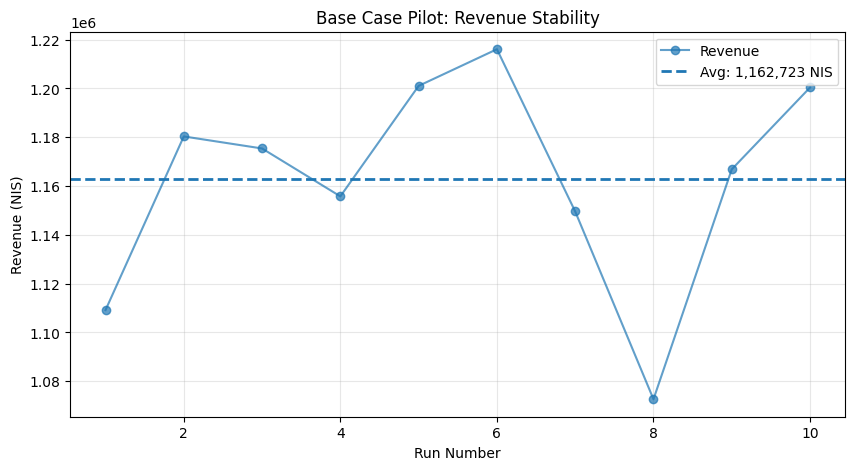

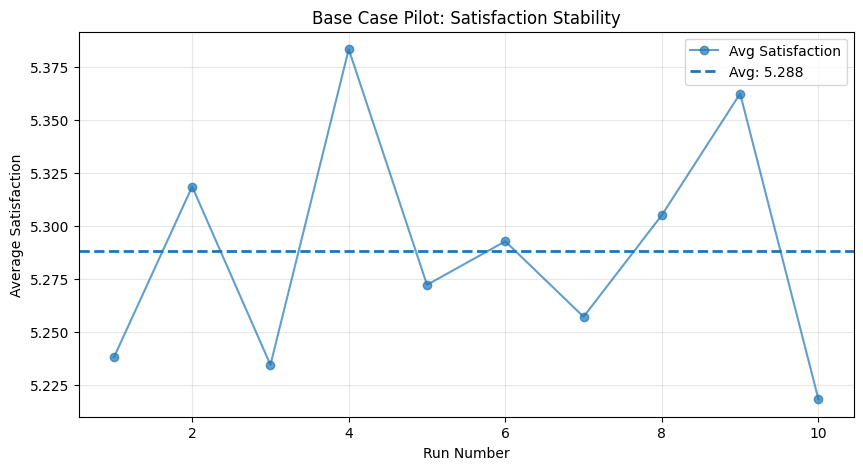

          SAMPLE SIZE DETERMINATION - BASE CASE PILOT           
             Alpha = 0.1 | Confidence Level = 90%               
             Relative Precision = 0.1                           
 Revenue                                                       
   Mean:            1,162,723.000                    
   Std:                44,000.783                     
   t-value:                 1.833                  
   Epsilon:           116,272.300                 
   Required N:                  1                   
 Satisfaction                                                  
   Mean:                    5.288                    
   Std:                     0.055                     
   t-value:                 1.833                  
   Epsilon:                 0.529                 
   Required N:                  1                   
 FINAL DECISION: N = 30                                            
 The final N is the maximum required N across the selected       
 performance 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import scipy.stats as stats

# ============================================================
# Helper 1 - Plot pilot metrics
# ============================================================

def plot_pilot_metrics(revenues, satisfactions, scenario_name="Base Case"):
    # Plot revenue and satisfaction across pilot runs to check stability.
    runs = range(1, len(revenues) + 1)

    plt.figure(figsize=(10, 5))
    plt.plot(runs, revenues, marker='o', linestyle='-', alpha=0.7, label='Revenue')
    plt.axhline(y=np.mean(revenues), linestyle='--', linewidth=2,
                label=f"Avg: {np.mean(revenues):,.0f} NIS")
    plt.title(f"{scenario_name}: Revenue Stability")
    plt.xlabel("Run Number")
    plt.ylabel("Revenue (NIS)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure(figsize=(10, 5))
    plt.plot(runs, satisfactions, marker='o', linestyle='-', alpha=0.7, label='Avg Satisfaction')
    plt.axhline(y=np.mean(satisfactions), linestyle='--', linewidth=2,
                label=f"Avg: {np.mean(satisfactions):.3f}")
    plt.title(f"{scenario_name}: Satisfaction Stability")
    plt.xlabel("Run Number")
    plt.ylabel("Average Satisfaction")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


# ============================================================
# Helper 2 - Batch runner
# ============================================================

def run_batch(n_runs, config=None, start_seed=40):
    # Run multiple independent replications of the simulation.
    # Each run uses a different seed to ensure independence.
    # Seeds are spaced by 2 to support CRN across alternatives.
    revenues = []
    satisfactions = []
    entities = []
    people = []

    print(f"[Processing] Running {n_runs} simulations...", end="")

    for i in range(n_runs):
        if i % 5 == 0:
            print(".", end="")

        current_seed = start_seed + i * 2

        sim = Simulator(config=config, seed=current_seed)
        sim.run()

        total = sim.total_entities_departed
        avg_sat = sim.total_satisfaction / total if total > 0 else 0

        revenues.append(sim.total_revenue)
        satisfactions.append(avg_sat)

        # Kept for descriptive reporting but not used for sample size calculation.
        entities.append(total)
        people.append(sim.total_people_departed)

    print(" Done.")

    return {
        "revenues": revenues,
        "satisfactions": satisfactions,
        "entities": entities,
        "people": people
    }


# ============================================================
# Helper 3 - Required sample size calculation
# ============================================================

def calculate_n_stats(values, precision=0.1, alpha=0.1):
    # Calculate the minimum number of replications needed
    # to achieve the required relative precision.
    n0 = len(values)
    mean_val = np.mean(values)
    std_val = np.std(values, ddof=1)

    # If there is no variance, one replication is enough.
    if mean_val == 0 or std_val == 0:
        return {
            "mean": mean_val,
            "std": std_val,
            "t_crit": 0,
            "epsilon": 0,
            "n_calc": 1,
            "n_rounded": 1
        }

    # t critical value for two-sided confidence interval.
    t_crit = stats.t.ppf(1 - alpha / 2, df=n0 - 1)
    # Allowed absolute error based on relative precision.
    epsilon = abs(mean_val) * precision
    # Required sample size formula.
    n_calc = ((t_crit * std_val) / epsilon) ** 2

    return {
        "mean": mean_val,
        "std": std_val,
        "t_crit": t_crit,
        "epsilon": epsilon,
        "n_calc": n_calc,
        "n_rounded": math.ceil(n_calc)
    }


# ============================================================
# Step 1 - Pilot run and sample size determination
# ============================================================

print("\n" + "=" * 60)
print("STEP 1 - PILOT RUN AND SAMPLE SIZE DETERMINATION")
print("=" * 60)

# Baseline config uses fitted parameters from the data file.
config_baseline = {
    "friends_interarrival_sampler": lambda: sample_exponential_mean(1 / 0.72927),
    "couple_interarrival_sampler":  lambda: sample_exponential_mean(60),
    "single_interarrival_sampler":  lambda: sample_exponential_mean(660 / 500),
    "initial_satisfaction": 5.0
}

# Run 10 pilot replications starting from seed 40.
pilot_results = run_batch(
    n_runs=10,
    config=config_baseline,
    start_seed=40
)

pilot_revenues = pilot_results["revenues"]
pilot_satisfactions = pilot_results["satisfactions"]

# Plot stability charts for the two selected performance measures.
plot_pilot_metrics(
    revenues=pilot_revenues,
    satisfactions=pilot_satisfactions,
    scenario_name="Base Case Pilot"
)

# Calculate required N for each performance measure separately.
stats_revenue = calculate_n_stats(pilot_revenues, precision=0.1, alpha=0.1)
stats_satisfaction = calculate_n_stats(pilot_satisfactions, precision=0.1, alpha=0.1)

# Take the maximum required N across all measures.
calculated_max = max(
    stats_revenue["n_rounded"],
    stats_satisfaction["n_rounded"]
)

# Use at least 30 replications to satisfy the Central Limit Theorem.
final_n = max(30, calculated_max)


# ============================================================
# Sample size report
# ============================================================

print("          SAMPLE SIZE DETERMINATION - BASE CASE PILOT           ")
print("             Alpha = 0.1 | Confidence Level = 90%               ")
print("             Relative Precision = 0.1                           ")

def print_metric_report(metric_name, stat):
    # Print a summary report for one performance measure.
    print(f" {metric_name:<20}                                          ")
    print(f"   Mean:          {stat['mean']:>15,.3f}                    ")
    print(f"   Std:           {stat['std']:>15,.3f}                     ")
    print(f"   t-value:       {stat['t_crit']:>15,.3f}                  ")
    print(f"   Epsilon:       {stat['epsilon']:>15,.3f}                 ")
    print(f"   Required N:    {stat['n_rounded']:>15}                   ")


print_metric_report("Revenue", stats_revenue)
print_metric_report("Satisfaction", stats_satisfaction)

print(f" FINAL DECISION: N = {final_n:<45} ")
print(" The final N is the maximum required N across the selected       ")
print(" performance measures, with a minimum of 30 replications.        ")

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

# **מודל הבסיס (Base Case)**

בשלב זה הורץ מודל הסימולציה במצבו הקיים (Base Case), ללא יישום חלופות או שינויים במערכת. מטרת ההרצה היא לקבוע נקודת ייחוס (Baseline) שתשמש להשוואת החלופות בהמשך העבודה.

המודל הורץ במספר ההרצות שנקבע בשלב הפיילוט, וחושבו שני מדדי הביצוע שנבחרו: **ההכנסות הכוללות של הפסטיבל** ו**מדד שביעות הרצון הממוצע של המבקרים**. תוצאות אלו ישמשו בסיס להשוואה סטטיסטית מול החלופות השונות.

</div>



🔵 STEP 2: Running Full Base Case (N=30)
[Processing] Running 30 simulations......... Done.


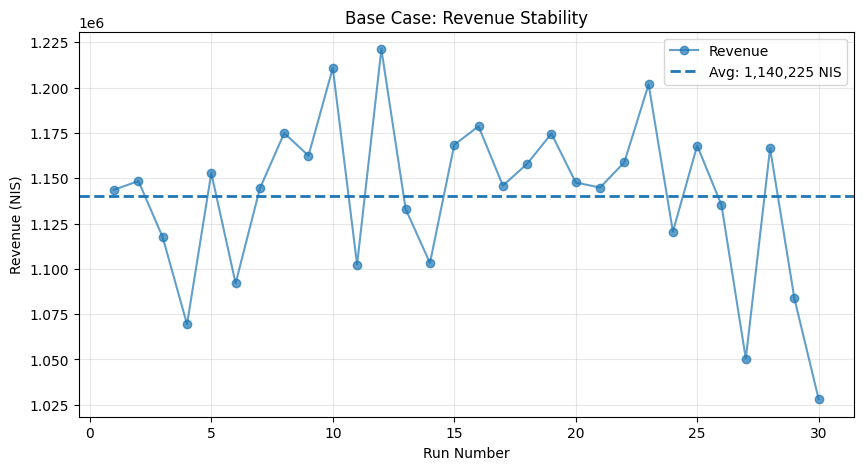

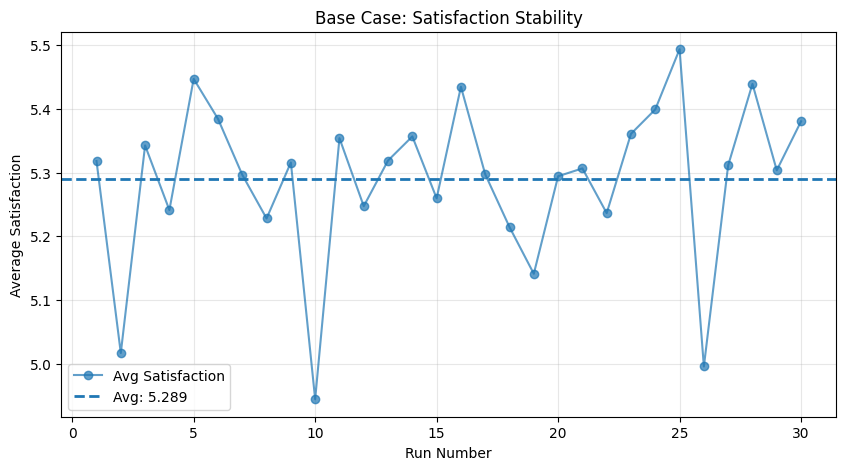

   -> Base Avg Revenue: 1,140,224.67
   -> Base Avg Satisfaction: 5.289


In [ ]:
# ==========================================
# STEP 2: Running Full Base Case
# ==========================================
print(f"\n🔵 STEP 2: Running Full Base Case (N={final_n})")

# Run the full base case using the sample size determined in Step 1.
# Start seed is 100 to separate from the pilot runs (seed 40).
base_results = run_batch(
    n_runs=final_n,
    config=config_baseline,
    start_seed=100
)

base_revs = base_results["revenues"]
base_sats = base_results["satisfactions"]

# Plot stability charts for the base case.
plot_pilot_metrics(
    revenues=base_revs,
    satisfactions=base_sats,
    scenario_name="Base Case"
)

# Save base case averages to use as reference in later comparisons.
avg_base_rev = np.mean(base_revs)
avg_base_sat = np.mean(base_sats)

print(f"   -> Base Avg Revenue: {avg_base_rev:,.2f}")
print(f"   -> Base Avg Satisfaction: {avg_base_sat:.3f}")

# **חלופות**

<div dir="rtl" style="text-align: right; font-size:16px; line-height:1.8;">

### חלופה א
##שיפור חוויית ההופעות והגדלת ההכנסות ממרצ'נדייז

במסגרת חלופה זו, בוצעה הרצה של המודל תוך הטמעת שיפורים הממוקדים בשיפור חוויית המבקרים במהלך ההופעות ובהגדלת ההכנסות ממכירת מוצרי מרצ'נדייז. השינויים המרכזיים כוללים:

<ul>
<li><b>הרחבת צוות המאבטחים:</b> הגדלת קיבולת כלל מתחמי ההופעות ב־30%, במטרה להפחית עומסים, לאפשר כניסה של יותר מבקרים לכל הופעה ולשפר את חוויית הצפייה.</li>

<li><b>השקעה בלהקות מיינסטרים פופולריות:</b> שדרוג ההופעות בבמה המרכזית, כך שמשקל הופעות המיינסטרים בחישוב מדד שביעות הרצון גדל, ובמקביל ההסתברות לרכישת חולצת להקה ממותגת עולה באופן משמעותי, ובכך צפויה עלייה נוספת בהכנסות.</li>
</ul>

עלותה הכוללת של חלופה זו היא <b>950,000 ₪</b>.

מטרת הרצה זו היא לבחון האם השקעה בהגדלת קיבולת מתחמי ההופעות ובשיפור איכות ההופעות המרכזיות מצדיקה את עצמה באמצעות עלייה בהכנסות הכוללות של הפסטיבל ובשיפור שביעות רצון המבקרים, ביחס למצב הקיים.

</div>

In [ ]:
# ==========================================
# STEP 3A: Analyzing Alternative 1
# ==========================================
print(f"\n🟢 STEP 3A: Alternative 1 (Stages + Mainstream Upgrade) (N={final_n})")

# Copy baseline config and apply Alternative 1 changes:
# - EXPAND_STAGE_CAPACITY: increases stage capacity by 30%.
# - POPULAR_MAINSTREAM: increases genre value and band shirt probability.
config_alt1 = config_baseline.copy()

config_alt1.update({
    "EXPAND_STAGE_CAPACITY": True,
    "POPULAR_MAINSTREAM": True
})

# Run Alternative 1 with the same seeds as the base case for CRN.
alt1_results = run_batch(
    final_n,
    config=config_alt1,
    start_seed=100
)

alt1_revs = alt1_results["revenues"]
alt1_sats = alt1_results["satisfactions"]

print(f"   -> Alt 1 Avg Revenue: {np.mean(alt1_revs):,.2f}")
print(f"   -> Alt 1 Avg Satisfaction: {np.mean(alt1_sats):.2f}")


🟢 STEP 3A: Alternative 1 (Stages + Mainstream Upgrade) (N=30)
[Processing] Running 30 simulations......... Done.
   -> Alt 1 Avg Revenue: 1,275,862.83
   -> Alt 1 Avg Satisfaction: 5.59


<div dir="rtl" style="text-align: right; font-size:16px; line-height:1.8;">

### חלופה ב
# שיפור חוויית השירות, האוכל ושביעות רצון המבקרים

במסגרת חלופה זו, בוצעה הרצה של המודל תוך הטמעת שיפורים הממוקדים בשיפור איכות השירות בפסטיבל, הגדלת שביעות רצון המבקרים ושיפור חוויית הבילוי הכוללת. השינויים המרכזיים כוללים:

- **צוות מטבח טוב יותר:** שיפור איכות ההכנה בדוכני המזון, כך שההסתברות לקבלת מנה שאינה טובה יורדת באופן משמעותי, ובמקביל שיעור המבקרים הבוחרים לאכול במתחם המזון גדל.

- **הוספת עמדת צילום ואמן ציורי פנים נוסף:** הגדלת מספר עמדות הצילום מ־3 ל־4 ומספר אמני ציורי הפנים מ־2 ל־3, במטרה להפחית זמני המתנה, לצמצם נטישות תורים ולאפשר ליותר מבקרים ליהנות מהשירותים.

- **הטבת מבקרים:** העלאת מדד שביעות הרצון ההתחלתי של כל מבקר מ־5 ל־6.5 באמצעות חלוקת תיק מתנות בכניסה לפסטיבל.

עלותה הכוללת של חלופה זו היא **850,000 ₪**.

מטרת הרצה זו היא לבחון האם השקעה בשיפור איכות השירותים, חוויית האוכל ושביעות הרצון ההתחלתית של המבקרים מצדיקה את עצמה באמצעות עלייה בהכנסות הכוללות של הפסטיבל ובשיפור שביעות רצון המבקרים, ביחס למצב הקיים.

In [ ]:
# ==========================================
# STEP 3B: Analyzing Alternative 2
# ==========================================
print(f"\n🟣 STEP 3B: Alternative 2 (Kitchen + Benefit + Service Stations) (N={final_n})")

# Copy baseline config and apply Alternative 2 changes:
# - BETTER_KITCHEN: reduces bad food probability from 0.4 to 0.1.
# - ADD_PHOTO_AND_BODYART: adds one photo station and one body art artist.
# - initial_satisfaction: raises starting satisfaction from 5.0 to 6.5.
config_alt2 = config_baseline.copy()

config_alt2.update({
    "BETTER_KITCHEN": True,
    "ADD_PHOTO_AND_BODYART": True,
    "initial_satisfaction": 6.5
})

# Run Alternative 2 with the same seeds as the base case for CRN.
alt2_results = run_batch(
    final_n,
    config=config_alt2,
    start_seed=100
)

alt2_revs = alt2_results["revenues"]
alt2_sats = alt2_results["satisfactions"]

print(f"   -> Alt 2 Avg Revenue: {np.mean(alt2_revs):,.2f}")
print(f"   -> Alt 2 Avg Satisfaction: {np.mean(alt2_sats):.2f}")


🟣 STEP 3B: Alternative 2 (Kitchen + Benefit + Service Stations) (N=30)
[Processing] Running 30 simulations......... Done.
   -> Alt 2 Avg Revenue: 1,152,232.83
   -> Alt 2 Avg Satisfaction: 6.62


<div dir="rtl" style="text-align: right; font-size:16px; line-height:1.8;">

## ניתוח סטטיסטי השוואתי
##באמצעות רווחי סמך מזווגים (Paired Confidence Intervals)

על מנת לבחון האם החלופות שהוצעו אכן מביאות לשיפור מובהק בביצועי הפסטיבל, בוצע ניתוח סטטיסטי באמצעות רווחי סמך מזווגים המבוססים על התפלגות t. בשיטה זו, עבור כל אחד ממדדי הביצוע שנבחרו – **הרווח הכולל של הפסטיבל** ו**שביעות רצון המבקרים** – הוגדר משתנה מקרי חדש המייצג את ההפרש בין תוצאות ריצת הסימולציה בחלופה המוצעת לבין תוצאות אותה הריצה במצב הבסיס (Base Case).

הניתוח כלל שלוש השוואות מרכזיות עבור כל אחד מהמדדים:

- **חלופה א' מול המצב הקיים:** בחינת השפעת הרחבת קיבולת מתחמי ההופעות והשקעה בלהקות מיינסטרים פופולריות.
- **חלופה ב' מול המצב הקיים:** בחינת השפעת שיפור איכות המזון, הוספת עמדת צילום ואמן ציורי פנים נוסף, וכן העלאת שביעות הרצון ההתחלתית של המבקרים.
- **השוואה ישירה בין חלופה א' לחלופה ב':** במטרה לזהות איזו מבין שתי החלופות משיגה ביצועים טובים יותר בכל אחד ממדדי ההערכה.

### הנחות היסוד לניתוח

לצורך קבלת מסקנות תקפות הונחו ההנחות הבאות:

- **תלות בין הריצות:** כל חלופה הורצה באמצעות אותם זרעי אקראיות (Common Random Numbers), כך שכל ריצה בחלופה הושוותה לריצה המקבילה במצב הבסיס.
- **אי־תלות בין ההרצות:** ההרצות השונות בתוך כל חלופה בוצעו באמצעות זרעי אקראיות שונים, ולכן הן בלתי תלויות זו בזו.
- **התפלגות נורמלית של ההפרשים:** בהתאם למשפט הגבול המרכזי ולגודל המדגם שנבחר (N=30), הונח כי ממוצעי ההפרשים מתפלגים בקירוב נורמלית.

במסגרת הניתוח חושבו עבור כל השוואה ממוצע ההפרשים, סטיית התקן, שגיאת התקן ורווח סמך המבוסס על התפלגות t עבור ההפרש הממוצע בין החלופות. קבלת ההחלטה התבססה על מיקומו של הערך **0** ביחס לרווח הסמך: כאשר הערך 0 נמצא בתוך רווח הסמך, לא ניתן להסיק על קיומו של הבדל מובהק סטטיסטית בין החלופות. לעומת זאת, כאשר הערך 0 נמצא מחוץ לרווח הסמך, הוסק כי קיים הבדל מובהק סטטיסטית בין החלופות עבור המדד הנבחן.

מכיוון שבוצעו שש השוואות סטטיסטיות (שלוש השוואות עבור כל אחד משני המדדים), נעשה שימוש בתיקון **Bonferroni** לצורך שמירה על רמת ביטחון כוללת של **90%**. בהתאם לכך, רמת המובהקות לכל השוואה נקבעה ל־**α = 0.0167**, ובכך צומצם הסיכוי לקבלת מסקנות שגויות עקב ביצוע השוואות מרובות.

In [ ]:
# ==========================================
# STEP 5: Detailed Statistical Analysis
# ==========================================
import numpy as np
import scipy.stats as stats

print("\n📊 STEP 5: Final Statistical Analysis")
print("=" * 85)

# -----------------------------
# Bonferroni Settings
# -----------------------------
# We perform 6 paired comparisons across 2 metrics and 3 scenario pairs.
# Bonferroni correction divides the overall alpha by the number of tests.
alpha_total = 0.1          # Overall significance level.
num_tests = 6              # Total number of comparisons.
alpha_adj = alpha_total / num_tests  # Adjusted alpha per test.

print(f"Bonferroni Correction")
print(f"Overall Alpha = {alpha_total}")
print(f"Number of Tests = {num_tests}")
print(f"Adjusted Alpha = {alpha_adj:.5f}")


def print_detailed_z_table(name_a, data_a, name_b, data_b, metric_name, higher_is_better=True):
    # Print a paired comparison table and confidence interval for two scenarios.
    # Uses paired t-test with Bonferroni-adjusted alpha.

    n = len(data_a)
    # Compute paired differences: Z_i = A_i - B_i for each replication.
    diffs = np.array(data_a) - np.array(data_b)

    print(f"\n{'='*85}")
    print(f"{metric_name}: {name_a} vs {name_b}")
    print("="*85)

    print(f"{'Run':<5} | {name_a:<18} | {name_b:<18} | {'Difference (Z)':<18}")
    print("-"*85)

    # Print one row per replication.
    for i in range(n):
        if metric_name == "Revenue":
            print(f"{i+1:<5} | {data_a[i]:<18,.0f} | {data_b[i]:<18,.0f} | {diffs[i]:<18,.0f}")
        else:
            print(f"{i+1:<5} | {data_a[i]:<18.3f} | {data_b[i]:<18.3f} | {diffs[i]:<18.3f}")

    # Calculate paired t-test statistics.
    mean_z = np.mean(diffs)
    std_z = np.std(diffs, ddof=1)
    se = std_z / np.sqrt(n)

    # Critical t-value for the adjusted alpha and n-1 degrees of freedom.
    t_crit = stats.t.ppf(1 - alpha_adj/2, df=n-1)

    # Half-width of the confidence interval.
    hw = t_crit * se

    ci_low = mean_z - hw
    ci_high = mean_z + hw

    print("-"*85)
    print(f"Mean Difference : {mean_z:,.3f}")
    print(f"Std Difference  : {std_z:,.3f}")
    print(f"Standard Error  : {se:,.3f}")
    print(f"T Critical      : {t_crit:.3f}")
    print(f"Confidence Int. : [{ci_low:,.3f}, {ci_high:,.3f}]")

    # If 0 is inside the interval, the difference is not significant.
    if ci_low <= 0 <= ci_high:
        print("\nResult: No statistically significant difference.")
    else:
        print("\nResult: Statistically significant difference.")

        # Determine which scenario is better based on the metric direction.
        if higher_is_better:
            winner = name_a if mean_z > 0 else name_b
        else:
            winner = name_a if mean_z < 0 else name_b

        print(f"Winner: {winner}")

    print("="*85)


# ==========================================
# Revenue
# ==========================================

print("\n" + "▒"*30 + " REVENUE " + "▒"*30)

# Compare each alternative against the base case and against each other.
print_detailed_z_table(
    "Alternative 1",
    alt1_revs,
    "Base",
    base_revs,
    "Revenue"
)

print_detailed_z_table(
    "Alternative 2",
    alt2_revs,
    "Base",
    base_revs,
    "Revenue"
)

print_detailed_z_table(
    "Alternative 1",
    alt1_revs,
    "Alternative 2",
    alt2_revs,
    "Revenue"
)


# ==========================================
# Satisfaction
# ==========================================

print("\n" + "▒"*30 + " SATISFACTION " + "▒"*30)

# Same three comparisons for the satisfaction metric.
print_detailed_z_table(
    "Alternative 1",
    alt1_sats,
    "Base",
    base_sats,
    "Satisfaction"
)

print_detailed_z_table(
    "Alternative 2",
    alt2_sats,
    "Base",
    base_sats,
    "Satisfaction"
)

print_detailed_z_table(
    "Alternative 1",
    alt1_sats,
    "Alternative 2",
    alt2_sats,
    "Satisfaction"
)


📊 STEP 5: Final Statistical Analysis
Bonferroni Correction
Overall Alpha = 0.1
Number of Tests = 6
Adjusted Alpha = 0.01667

▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒ REVENUE ▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒▒

Revenue: Alternative 1 vs Base
Run   | Alternative 1      | Base               | Difference (Z)    
-------------------------------------------------------------------------------------
1     | 1,279,760          | 1,143,630          | 136,130           
2     | 1,303,970          | 1,148,435          | 155,535           
3     | 1,243,080          | 1,117,395          | 125,685           
4     | 1,309,635          | 1,069,375          | 240,260           
5     | 1,224,160          | 1,152,855          | 71,305            
6     | 1,215,615          | 1,091,995          | 123,620           
7     | 1,331,005          | 1,144,380          | 186,625           
8     | 1,291,980          | 1,174,900          | 117,080           
9     | 1,428,700          | 1,162,450          | 266,250        

<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

## **ניתוח תוצאות והסקה סטטיסטית**

לאחר ביצוע 30 הרצות לכל חלופה ובחינתן באמצעות רווחי סמך מזווגים המבוססים על התפלגות t עם תיקון בונפרוני, להלן הממצאים המרכזיים עבור מדדי הביצוע שנבחנו:

### 1. ניתוח ההכנסות הכוללות (Revenue)

* **חלופה א' מול המצב הקיים:** נמצא שיפור מובהק סטטיסטית, מאחר שהערך 0 נמצא מחוץ לרווח הסמך $[108{,}657,\ 162{,}618]$. ההכנסות הכוללות של הפסטיבל גדלו בממוצע בכ־135,638 ₪, דבר המעיד כי הרחבת קיבולת מתחמי ההופעות והשקעה בלהקות מיינסטרים פופולריות מובילות לשיפור משמעותי בהכנסות.

* **חלופה ב' מול המצב הקיים:** לא נמצא הבדל מובהק סטטיסטית, מאחר שהערך 0 נמצא בתוך רווח הסמך $[-18{,}014,\ 42{,}030]$. ההפרש הממוצע עמד על כ־12,008 ₪, ולכן לא ניתן להסיק כי חלופה זו משפיעה באופן מובהק על הכנסות הפסטיבל.

* **השוואה בין החלופות:** חלופה א' נמצאה עדיפה באופן מובהק על חלופה ב' מבחינת הכנסות, עם הפרש ממוצע של כ־123,630 ₪ לטובתה. רווח הסמך שהתקבל הוא $[87{,}676,\ 159{,}583]$, והוא אינו כולל את הערך 0.

---

### 2. ניתוח שביעות רצון המבקרים (Satisfaction)

* **חלופה א' מול המצב הקיים:** נמצא שיפור מובהק סטטיסטית, מאחר שהערך 0 נמצא מחוץ לרווח הסמך $[0.228,\ 0.377]$. שביעות הרצון הממוצעת עלתה בכ־0.303 נקודות, ולכן ניתן להסיק כי הרחבת קיבולת מתחמי ההופעות והשקעה בלהקות מיינסטרים משפרות גם את חוויית המבקרים.

* **חלופה ב' מול המצב הקיים:** נמצא שיפור מובהק סטטיסטית, מאחר שהערך 0 נמצא מחוץ לרווח הסמך $[1.252,\ 1.416]$. שביעות הרצון הממוצעת עלתה בכ־1.334 נקודות, דבר המעיד כי שיפור איכות השירותים, האוכל והעלאת שביעות הרצון ההתחלתית תורמים באופן משמעותי לחוויית המבקרים.

* **השוואה בין החלופות:** חלופה ב' נמצאה עדיפה באופן מובהק על חלופה א' מבחינת שביעות רצון. ההפרש חושב כחלופה א' פחות חלופה ב', ולכן התקבל הפרש ממוצע של כ־1.032- נקודות ורווח סמך $[-1.108,\ -0.956]$. מאחר שכל רווח הסמך שלילי, ניתן להסיק כי חלופה ב' מובילה לשביעות רצון גבוהה יותר מחלופה א'.

---

### מסקנה סופית והמלצה תפעולית


מהניתוח עולה כי **חלופה א' היא החלופה העדיפה**, שכן היא היחידה שהציגה **שיפור מובהק סטטיסטית בשני מדדי הביצוע** – הן בהכנסות הכוללות והן בשביעות רצון המבקרים – ביחס למצב הקיים. בנוסף, חלופה א' נמצאה עדיפה באופן מובהק על חלופה ב' במדד ההכנסות.

אמנם חלופה ב' השיגה שיפור גדול יותר בשביעות רצון המבקרים ואף נמצאה עדיפה על חלופה א' במדד זה, אך היא **לא הציגה שיפור מובהק בהכנסות** ביחס למצב הקיים.

**המלצתנו** היא לבחור **בחלופה א'**, מאחר שהיא משפרת באופן מובהק את שני מדדי הביצוע שנבחנו ומספקת את האיזון הטוב ביותר בין הגדלת ההכנסות לבין שיפור חוויית המבקרים.





<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

# **תוספת: בדיקות אימות בסיסיות (Verification)**

לפני הסקת מסקנות כדאי לוודא שהמודל מתנהג באופן עקבי. נוספו שלוש בדיקות פשוטות על תוצאות מודל הבסיס:

1. **שחזוריות בתוך הרצה אחת:** הרצה חוזרת עם אותם זרעים אמורה להחזיר בדיוק את אותן תוצאות (תנאי הכרחי לשימוש במספרים אקראיים משותפים, CRN).
2. **עקביות לוגית:** מספר האנשים שעזבו את הפסטיבל לא יכול להיות קטן ממספר הישויות (כל ישות כוללת לפחות אדם אחד).
3. **טווחים הגיוניים:** ההכנסות ושביעות הרצון הממוצעת חיוביות בכל ההרצות.

</div>


In [ ]:
# ==========================================
# EXTRA: Basic verification checks (Base Case)
# ==========================================
print("Verification checks on the base case")
print("=" * 60)

# Check 1 - Reproducibility within a session:
# re-running the first 3 base-case seeds must give identical results.
check = run_batch(3, config=config_baseline, start_seed=100)
same = (np.allclose(check["revenues"], base_revs[:3]) and
        np.allclose(check["satisfactions"], base_sats[:3]))
print(f"1. Same seeds reproduce the same runs: {'PASS' if same else 'FAIL'}")

# Check 2 - Logical consistency: every entity contains at least one person.
consistent = all(p >= e for p, e in zip(base_results["people"], base_results["entities"]))
print(f"2. People departed >= entities departed in every run: {'PASS' if consistent else 'FAIL'}")

# Check 3 - Plausible ranges: revenue and satisfaction are positive in every run.
plausible = all(r > 0 for r in base_revs) and all(s > 0 for s in base_sats)
print(f"3. Revenue and satisfaction positive in every run: {'PASS' if plausible else 'FAIL'}")


<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

# **תוספת: ניתוח עלות-תועלת**

הניתוח הסטטיסטי בדק האם החלופות משפרות את ההכנסות ואת שביעות הרצון, אך לא השווה את השיפור בהכנסות לעלות ההשקעה (950,000 ₪ לחלופה א' ו-850,000 ₪ לחלופה ב'). בתא הבא מחושב **זמן ההחזר** במספר פסטיבלים, בהנחה שהעלות היא השקעה חד-פעמית והשיפור בהכנסות חוזר על עצמו בכל פסטיבל.

שימו לב להגבלות: (1) מדובר בהכנסות ולא ברווח, כלומר לא מנוכות עלויות תפעול; (2) שביעות הרצון אינה מתורגמת לכסף. אם ההשקעה חוזרת בכל פסטיבל, אף אחת מהחלופות אינה מחזירה את עצמה על בסיס הכנסות בלבד. תוספת זו אינה משנה את ההמלצה שלעיל, אלא מציגה את התמונה הכלכלית המלאה.

</div>


In [ ]:
# ==========================================
# EXTRA: Cost-benefit / payback analysis
# ==========================================
import numpy as np
import scipy.stats as stats

costs = {"Alternative 1": 950_000, "Alternative 2": 850_000}
revs = {"Alternative 1": alt1_revs, "Alternative 2": alt2_revs}

n = len(base_revs)
alpha_adj = 0.1 / 6                        # same Bonferroni-adjusted alpha as above
t_crit = stats.t.ppf(1 - alpha_adj / 2, n - 1)

print("Payback analysis (assumes a one-time cost and a repeating revenue gain)")
print("=" * 78)
for name, cost in costs.items():
    gain = np.array(revs[name]) - np.array(base_revs)    # paired differences
    mean = gain.mean()
    se = gain.std(ddof=1) / np.sqrt(n)
    lower = mean - t_crit * se                           # lower end of the CI

    payback = cost / mean if mean > 0 else float("inf")
    payback_cons = cost / lower if lower > 0 else float("inf")

    print(f"{name}:")
    print(f"   Investment cost:              {cost:>12,.0f}")
    print(f"   Mean revenue gain / festival: {mean:>12,.0f}")
    print(f"   Payback (mean gain):          {payback:>12.1f} festivals")
    if lower > 0:
        print(f"   Payback (CI lower bound):     {payback_cons:>12.1f} festivals")
    else:
        print("   Revenue gain not statistically significant -> no reliable payback")


<div dir="rtl" style="text-align: right; font-size: 16px; line-height: 1.8;">

---

# **הערה על שחזוריות ויציבות התוצאות**

בעת הרצה חוזרת של המחברת בסביבה אחרת נמצא שהתוצאות המספריות אינן זהות במדויק להרצה המקורית, גם עם אותם זרעים. הסיבה: בקוד מומרות קבוצות של מחרוזות (`set`) לרשימות (למשל `list(self.eligible_stations)`), וסדר האיברים בקבוצה כזו משתנה בין הרצות של פייתון. בתוך הרצה אחת הכול עקבי, ולכן CRN נשמר והבדיקות לעיל עוברות. בין הרצות שונות מתקבלים הבדלים קטנים.

כדי לוודא שהמסקנות אינן תלויות בכך, הניסוי המלא (30 הרצות לכל תרחיש ושש ההשוואות המזווגות) הורץ 5 פעמים עם סדרי קבוצות שונים. **בכל 5 ההרצות התקבלו אותן מסקנות בכל שש ההשוואות:** חלופה א' משפרת באופן מובהק גם הכנסות וגם שביעות רצון, חלופה ב' משפרת באופן מובהק רק את שביעות הרצון (ובהכנסות אין הבדל מובהק), וחלופה א' עדיפה על ב' בהכנסות בעוד ב' עדיפה על א' בשביעות רצון. השיפור בהכנסות של חלופה א' נע בין כ-103,000 ל-135,000 ₪ בהרצות החוזרות (במחברת המקורית: כ-136,000 ₪).

לשחזוריות מלאה בין הרצות אפשר להחליף את ההמרות הללו ב-`list(sorted(...))`. שינוי כזה ישנה מעט את המספרים, ולכן לא בוצע כאן כדי לשמור על התוצאות המקוריות.

</div>
